In [58]:

from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_google_genai import GoogleGenerativeAIEmbeddings, ChatGoogleGenerativeAI
from langchain_core.tools import tool
from langchain_classic.agents import AgentExecutor, create_tool_calling_agent
from langchain_core.messages import HumanMessage, AIMessage
from langchain_core.prompts import ChatPromptTemplate

from pydantic import BaseModel, Field

from dotenv import load_dotenv

import markdown
from pathlib import Path
from fpdf import FPDF, FontFace
from PIL import Image as PILIMAGE

import theme
import data_cleaner

import streamlit as st

import pandas as pd
import numpy as np
import geopandas as gpd
import math

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from shapely.geometry import Point, MultiPolygon

import time
import os
import sys
import contextlib
import io
import re
from IPython.display import Image as IPythonImage, Markdown, display
import unicodedata
from typing import Optional

# API KEY
load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")

if api_key:
  print("API key cargada correctamente")
else:
  raise RuntimeError("No se encontró GEMINI_API_KEY en el archivo .env "
                    "Verificá que el archivo .env exista en la raíz del proyecto "
                    "y contenga la variable GEMINI_API_KEY"
  )

# Embeddings
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")

os.makedirs("./generated_images", exist_ok=True)

API key cargada correctamente


## Cargar base vectorial local

In [2]:
# Cargar la base vectorial Chroma ya existente
vectorstore = Chroma(
    collection_name="smn_documentos",
    embedding_function=embeddings,
    persist_directory="./chroma_db_smn"
)

print(
    "Documentos cargados desde Chroma:",
    vectorstore._collection.count()
)

# Crear retriever
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 5}
)

Documentos cargados desde Chroma: 722


In [ ]:
# Celda para ver que fuentes fueron cargadas
data = vectorstore._collection.get(
  include=["metadatas"]
)

for id_, metadata in zip(data["ids"], data["metadatas"]):
  print(id_, metadata.get('source'))

In [26]:
# Celda para borrar fuentes manualmente

archivo = 'nombre_archivo'

vectorstore._collection.delete(
  where={'source': f'files\\{archivo}.pdf'}
)

print(
  "Documentos restantes:",
  vectorstore._collection.count()
)

Documentos restantes: 722


## Cargar PDFs y generar base vectorial Chroma

**NOTA:** *Se detectan documentos existentes ya cargados. Solo se tienen en cuenta documentos nuevos.*

In [3]:
# Lista de documentos existentes
registros_existentes = vectorstore._collection.get(include=["metadatas"])
fuentes_procesadas = set()

if registros_existentes and registros_existentes.get("metadatas"):
    for meta in registros_existentes["metadatas"]:
        if meta and "source" in meta:
            fuentes_procesadas.add(os.path.abspath(meta["source"]))

# Cargar PDFs
loader = PyPDFDirectoryLoader("files")
todos_los_documentos = loader.load()

# Documentos nuevos
documentos_nuevos = [
    doc for doc in todos_los_documentos 
    if os.path.abspath(doc.metadata.get("source", "")) not in fuentes_procesadas
]

print(f"Páginas detectadas nuevas: {len(documentos_nuevos)}")

if len(documentos_nuevos) == 0:
    print("No hay documentos nuevos para agregar.")
else:

    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=500,
        chunk_overlap=50
    )
    docs_split_nuevos = text_splitter.split_documents(documentos_nuevos)
    print(f"Nuevos fragmentos generados: {len(docs_split_nuevos)}")

    # Tener en cuenta los limites de la API
    batch_size = 75
    total = len(docs_split_nuevos)

    for i in range(0, total, batch_size):
        lote = docs_split_nuevos[i:i + batch_size]

        print(f"Procesando lote {i // batch_size + 1}: documentos {i + 1} a {min(i + batch_size, total)}")

        # add_documents agrega sin borrar el contenido anterior
        vectorstore.add_documents(lote)

        print(f"Documentos guardados hasta ahora: {vectorstore._collection.count()}")

        if i + batch_size < total:
            print("Esperando 60 segundos para respetar la cuota...\n")
            time.sleep(60)

    print("\nNuevos documentos agregados correctamente.")
    print("Total actualizado de documentos almacenados:", vectorstore._collection.count())

Páginas detectadas nuevas: 0
No hay documentos nuevos para agregar.


## Funciones de ayuda

In [59]:
def normalizar_texto(texto: str) -> str:
  """Elimina tildes, mayúsculas y espacios innecesarios para facilitar coincidencias."""
  if not texto:
    return ""
  texto = texto.strip().upper()
  texto = unicodedata.normalize('NFD', texto)
  texto = ''.join(c for c in texto if unicodedata.category(c) != 'Mn')
  return texto

def filtrar_poligono_tdf(geometry, modo: str = "continental"):
  """
  Separa los polígonos de la provincia de Tierra del Fuego, Antártida e Islas del Atlántico Sur.
  - 'continental': Conserva únicamente la Isla Grande e Isla de los Estados (lat > -55 y long < -55).
  - 'antartida': Conserva el Sector Antártico e islas australes (lat <= -55 o long >= -55).
  """
  if isinstance(geometry, MultiPolygon):
    if modo == "continental":
      polygons = [p for p in geometry.geoms if p.centroid.y > -55 and p.centroid.x < -55]
    elif modo == "antartida":
      polygons = [p for p in geometry.geoms if p.centroid.y <= -55 or p.centroid.x >= -55]
    else:
      return geometry
    return MultiPolygon(polygons) if polygons else geometry
  return geometry

def procesar_y_renderizar_respuesta(resultado: dict) -> str:
  """
  Extrae la respuesta del agente, renderiza el texto en formato Markdown 
  e intercala/muestra las imágenes generadas (vía marcadores o fallback).
  Devuelve el texto completo para ser guardado en el historial.
  """
  # 1. Obtener texto de respuesta
  output_data = resultado.get("output", "")

  if isinstance(output_data, list):
    output_text = "\n".join(
      b["text"]
      for b in output_data
      if isinstance(b, dict) and "text" in b
    )
  else:
    output_text = str(output_data)

  # 2. Buscar marcadores de imágenes
  patron = re.compile(
    r"\[\[IMAGEN_GENERADA:(.*?)\]\]"
    r"|^\s*IMAGEN_GENERADA:(\S+)\s*$",
    re.MULTILINE
  )

  matches = list(patron.finditer(output_text))

  # 3. Mostrar texto + imágenes intercalados
  posicion_actual = 0
  imagenes_mostradas = set()

  for match in matches:
    texto = output_text[posicion_actual:match.start()].strip()

    if texto:
      display(Markdown(texto))

    path_imagen = (
      match.group(1)
      if match.group(1) is not None
      else match.group(2)
    )
    path_imagen = path_imagen.strip()

    if path_imagen and os.path.exists(path_imagen):
      if path_imagen not in imagenes_mostradas:
        display(IPythonImage(filename=path_imagen))
        imagenes_mostradas.add(path_imagen)
    else:
      print(f"⚠️ No se encontró la imagen generada: {path_imagen}")

    posicion_actual = match.end()

  # 4. Mostrar el texto restante después de la última imagen
  texto_restante = output_text[posicion_actual:].strip()
  if texto_restante:
    display(Markdown(texto_restante))

  # 5. Fallback: Imágenes generadas por herramientas pero omitidas en el texto por el LLM
  imagenes_generadas = []
  for action, observation in resultado.get("intermediate_steps", []):
    if isinstance(observation, str):
      for linea in observation.splitlines():
        if linea.startswith("IMAGEN_GENERADA:"):
          path_imagen = linea.split("IMAGEN_GENERADA:", 1)[1].strip()
          if path_imagen and path_imagen not in imagenes_generadas:
            imagenes_generadas.append(path_imagen)

  for path_imagen in imagenes_generadas:
    if path_imagen not in imagenes_mostradas:
      if os.path.exists(path_imagen):
        display(IPythonImage(filename=path_imagen))
        imagenes_mostradas.add(path_imagen)
      else:
        print(f"⚠️ No se encontró la imagen generada: {path_imagen}")

  return output_text

from datetime import datetime, date

def obtener_ultimo_mes_completo():
  """Devuelve el número de mes, nombre del mes y año del último mes completo."""
  hoy = datetime.now()
  # Si estamos en enero, el último mes completo es diciembre del año anterior
  if hoy.month == 1:
    mes_num = 12
    anio = hoy.year - 1
  else:
    mes_num = hoy.month - 1
    anio = hoy.year
      
  meses_nombres = [
    "enero", "febrero", "marzo", "abril", "mayo", "junio",
    "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"
  ]
  
  return {
    "mes_num": mes_num,
    "mes_nombre": meses_nombres[mes_num - 1],
    "anio": anio
  }

## Carga de datasets

In [4]:
# ================================================================
# Temperaturas de los ultimos 365 dias
# ================================================================

print('='*50)
print("Temperaturas de los ultimos 365 dias")
print('='*50)

data_cleaner.descargar_temps_365d()
data_cleaner.limpiar_temps_365d()

df_temps_365d = pd.read_csv(
    "datasets/temperaturas_365d.csv",
    parse_dates=["fecha"]
)

# Limpieza mínima de seguridad
df_temps_365d["estacion"] = df_temps_365d["estacion"].str.strip()

df_temps_365d = df_temps_365d.sort_values(
    by=["estacion", "fecha"]
).reset_index(drop=True)

# Verificaciones
print("\nCantidad de registros:", len(df_temps_365d))

print("\nRango de fechas:")
print("Desde:", df_temps_365d["fecha"].min())
print("Hasta:", df_temps_365d["fecha"].max())

print("\nValores faltantes:")
print(df_temps_365d.isna().sum())

display(df_temps_365d.head())

print("Validación de calidad de datos climáticos")

# Registros con tmax menor que tmin
inconsistentes = df_temps_365d[df_temps_365d["tmax"] < df_temps_365d["tmin"]]
print(f"\nRegistros con tmax < tmin: {len(inconsistentes)}")
if not inconsistentes.empty:
    display(inconsistentes.head())

# Valores fuera de rango (-40°C a 50°C)
fuera_de_rango = df_temps_365d[
    (df_temps_365d["tmax"] < -40) | (df_temps_365d["tmax"] > 50) |
    (df_temps_365d["tmin"] < -40) | (df_temps_365d["tmin"] > 50)
]
print(f"Registros con temperaturas fuera de rango: {len(fuera_de_rango)}")

# Dias faltantes
huecos_por_estacion = {}
for estacion, grupo in df_temps_365d.groupby("estacion"):
    rango_completo = pd.date_range(grupo["fecha"].min(), grupo["fecha"].max(), freq="D")
    faltantes = rango_completo.difference(grupo["fecha"])
    if len(faltantes) > 0:
        huecos_por_estacion[estacion] = len(faltantes)

print(f"\nEstaciones con huecos en la serie temporal: {len(huecos_por_estacion)}")
if huecos_por_estacion:
    display(
        pd.Series(huecos_por_estacion, name="dias_faltantes")
        .sort_values(ascending=False)
        .head(10)
    )


# ================================================================
# Estadísticas normales climatológicas 1991-2020
# ================================================================

print('='*50)
print("Estadísticas normales climatológicas 1991-2020")
print('='*50)

df_temps_normales = pd.read_csv(
    "datasets/estadisticas_normales_1991-2020.csv"
)

# Limpiar espacios por seguridad
df_temps_normales["estacion"] = df_temps_normales["estacion"].str.strip()
df_temps_normales["valor"] = df_temps_normales["valor"].str.strip()

print("\nCantidad de registros:", len(df_temps_normales))
print("Cantidad de estaciones:", df_temps_normales["estacion"].nunique())

display(df_temps_normales.head())

# ================================================================
# Lista de estaciones meteorologicas
# ================================================================

print('='*50)
print("Lista de estaciones meteorologicas")
print('='*50)

df_lista_estaciones = pd.read_csv(
    "datasets/estaciones_meteorologicas.csv"
)

REEMPLAZOS_PROVINCIAS = {
    "SANTIAGO DEL ES": "SANTIAGO DEL ESTERO",
    "TIERRA DEL FUEG": "TIERRA DEL FUEGO",
}

df_lista_estaciones["provincia"] = df_lista_estaciones["provincia"].str.strip().replace(REEMPLAZOS_PROVINCIAS)
df_lista_estaciones["PROVINCIA_NORM"] = df_lista_estaciones["provincia"].astype(str).apply(normalizar_texto)

print("\nCantidad de registros:", len(df_lista_estaciones))

display(df_lista_estaciones.head())

# ================================================================
# Mapa base de provincias
# ================================================================

print('='*50)
print("Mapa base de provincias")
print('='*50)

path_geojson = "./data/provincias.geojson"

if os.path.exists(path_geojson):
    gdf_provincias = gpd.read_file(path_geojson)
    gdf_provincias["NOMBRE_NORM"] = gdf_provincias["nombre"].astype(str).apply(normalizar_texto)
    print("Cantidad de provincias/entidades:", len(gdf_provincias))
    display(gdf_provincias.head())
else:
    print(f"\n[ERROR] No se encontró el archivo del mapa provincial en {path_geojson}")
    gdf_provincias = None

# ================================================================
# Pronosticos a 5 dias
# ================================================================

print('='*50)
print("Pronosticos a 5 dias")
print('='*50)

data_cleaner.descargar_pronosticos_5d()
data_cleaner.limpiar_pronosticos_5d()

df_pronosticos = pd.read_csv("datasets/pronosticos_5d.csv")

# Conversión y limpieza de fechas y texto
df_pronosticos["fecha"] = pd.to_datetime(df_pronosticos["fecha"], errors="coerce")
df_pronosticos["estacion"] = df_pronosticos["estacion"].astype(str).str.strip()

# Ordenamiento por estación, fecha y hora
df_pronosticos = df_pronosticos.sort_values(
    by=["estacion", "fecha", "hora"]
).reset_index(drop=True)

# Verificaciones generales
print("\nCantidad de registros:", len(df_pronosticos))
print("Cantidad de estaciones con pronóstico:", df_pronosticos["estacion"].nunique())

print("\nRango de fechas del pronóstico:")
print("Desde:", df_pronosticos["fecha"].min())
print("Hasta:", df_pronosticos["fecha"].max())

print("\nValores faltantes:")
print(df_pronosticos.isna().sum())

display(df_pronosticos.head())

print("Validación de calidad de datos de pronósticos")

# Temperaturas fuera de rango (-40°C a 50°C)
temp_fuera_de_rango = df_pronosticos[
    (df_pronosticos["temperatura"] < -40) | (df_pronosticos["temperatura"] > 50)
]
print(f"\nRegistros con temperaturas fuera de rango (-40°C a 50°C): {len(temp_fuera_de_rango)}")
if not temp_fuera_de_rango.empty:
    display(temp_fuera_de_rango.head())

# Velocidad de viento
viento_anormal = df_pronosticos[
    (df_pronosticos["viento_vel"] < 0) | (df_pronosticos["viento_vel"] > 200)
]
print(f"Registros con velocidad de viento fuera de rango (0 a 200): {len(viento_anormal)}")
if not viento_anormal.empty:
    display(viento_anormal.head())

# Precipitaciones negativas
precip_negativa = df_pronosticos[df_pronosticos["precipitacion"] < 0]
print(f"Registros con precipitación negativa: {len(precip_negativa)}")
if not precip_negativa.empty:
    display(precip_negativa.head())

# Cantidad de días pronosticados por estación
dias_por_estacion = df_pronosticos.groupby("estacion")["fecha"].nunique()
estaciones_incompletas = dias_por_estacion[dias_por_estacion < 5]

print(f"\nEstaciones con menos de 5 días de pronóstico: {len(estaciones_incompletas)}")
if not estaciones_incompletas.empty:
    display(
        pd.Series(estaciones_incompletas, name="dias_disponibles")
        .sort_values(ascending=True)
        .head(10)
    )


Temperaturas de los ultimos 365 dias
Descargando temperaturas de 365 días desde el SMN...
✅ Archivo extraído y guardado correctamente en './datasets\temperaturas_365d.txt'
Dataset de temperaturas procesado correctamente.

Cantidad de registros: 42951

Rango de fechas:
Desde: 2025-10-11 00:00:00
Hasta: 2026-10-10 00:00:00

Valores faltantes:
fecha          0
tmax        2085
tmin         570
estacion       0
dtype: int64


,fecha,tmax,tmin,estacion
0,2025-10-11,23.8,19.1,AEROPARQUE AERO
1,2025-10-12,23.0,14.2,AEROPARQUE AERO
2,2025-10-13,26.0,12.9,AEROPARQUE AERO
3,2025-10-14,22.1,15.5,AEROPARQUE AERO
4,2025-10-15,25.0,17.8,AEROPARQUE AERO


Validación de calidad de datos climáticos

Registros con tmax < tmin: 0
Registros con temperaturas fuera de rango: 2

Estaciones con huecos en la serie temporal: 6


CHILECITO AERO              71
VICTORICA                   24
OBERA                       12
BENITO JUAREZ AERO           9
SANTA CRUZ AERO              2
GOBERNADOR GREGORES AERO     1
Name: dias_faltantes, dtype: int64

Estadísticas normales climatológicas 1991-2020

Cantidad de registros: 784
Cantidad de estaciones: 98


...

Mapa base de provincias
Cantidad de provincias/entidades: 24


,id,nombre,nombre_completo,fuente,categoria,centroide,iso_id,iso_nombre,geometry,NOMBRE_NORM
0,02,Ciudad Autónoma de Buenos Aires,Ciudad Autónoma de Buenos Aires,IGN,Ciudad Autónoma,"{'lon': -58.445876325, 'lat': -34.614442065}",AR-C,Ciudad Autónoma de Buenos Aires,"POLYGON ((-58.45535 -34.52776, -58.45085 -34.5...",CIUDAD AUTONOMA DE BUENOS AIRES
1,58,Neuquén,Provincia del Neuquén,IGN,Provincia,"{'lon': -70.119897224, 'lat': -38.641982863}",AR-Q,Neuquén,"POLYGON ((-70.39341 -36.15624, -70.39499 -36.1...",NEUQUEN
2,74,San Luis,Provincia de San Luis,IGN,Provincia,"{'lon': -66.025231271, 'lat': -33.761103538}",AR-D,San Luis,"POLYGON ((-67.05547 -31.85605, -67.00593 -31.8...",SAN LUIS
3,82,Santa Fe,Provincia de Santa Fe,IGN,Provincia,"{'lon': -60.950687277, 'lat': -30.708822709}",AR-S,Santa Fe,"POLYGON ((-61.04639 -27.998, -58.884 -28, -58....",SANTA FE
4,46,La Rioja,Provincia de La Rioja,IGN,Provincia,"{'lon': -67.181757581, 'lat': -29.684937278}",AR-F,La Rioja,"POLYGON ((-68.52136 -27.81792, -68.51099 -27.8...",LA RIOJA


Pronosticos a 5 dias
Descargando pronósticos a 5 días desde el SMN...
✅ Archivo extraído y guardado correctamente en './datasets\pronosticos_5d.txt'
✅ CSV generado con éxito en './datasets/pronosticos_5d.csv'.

Cantidad de registros: 4720
Cantidad de estaciones con pronóstico: 118

Rango de fechas del pronóstico:
Desde: 2026-10-11 00:00:00
Hasta: 2026-10-15 00:00:00

Valores faltantes:
estacion         0
fecha            0
hora             0
temperatura      0
viento_dir       0
viento_vel       0
precipitacion    0
dtype: int64


,estacion,fecha,hora,temperatura,viento_dir,viento_vel,precipitacion
0,AEROPARQUE,2026-10-11,00:00,9.1,190,7,0.0
1,AEROPARQUE,2026-10-11,03:00,8.4,179,7,0.0
2,AEROPARQUE,2026-10-11,06:00,8.5,168,9,0.0
3,AEROPARQUE,2026-10-11,09:00,11.5,149,11,0.0
4,AEROPARQUE,2026-10-11,12:00,13.8,130,12,0.0


Validación de calidad de datos de pronósticos

Registros con temperaturas fuera de rango (-40°C a 50°C): 0
Registros con velocidad de viento fuera de rango (0 a 200): 0
Registros con precipitación negativa: 0

Estaciones con menos de 5 días de pronóstico: 0


## Definicion de Tools

In [5]:
# Crear herramienta para buscar información en los PDF
@tool
def buscar_informacion_texto(query: str) -> str:
  """Útil para buscar explicaciones conceptuales, definiciones técnicas o informes climáticos en los documentos PDF."""
  results = retriever.invoke(query)
  
  if not results:
    return "No se encontró información relevante en los informes."

  # Formatear la respuesta incluyendo fuente y página
  respuesta = []
  for doc in results:
    fuente = doc.metadata.get("source", "PDF desconocido")
    pagina = doc.metadata.get("page", 0) + 1
    respuesta.append(f"--- [Fuente: {fuente} (Pág. {pagina})] ---\n{doc.page_content}")
  
  return "\n\n".join(respuesta)

In [6]:
# Herramienta para consultar los documentos disponibles en la base vectorial

@tool
def listar_documentos_disponibles() -> str:
  """
  Muestra el inventario de informes o documentos disponibles en el sistema RAG.
  Úsalo cuando el usuario pregunte qué información, informes o fechas hay en la base de datos.
  """
  if 'vectorstore' not in globals() or vectorstore is None:
    return "Error: La base de datos vectorial 'vectorstore' no está cargada."

  try:
    # Obtener únicamente los metadatos almacenados en la colección de Chroma
    datos = vectorstore.get(include=["metadatas"])
    metadatos = datos.get("metadatas", [])

    if not metadatos:
      return "No hay documentos cargados en la base de datos."

    # Extraer los títulos o nombres de archivo (ajusta la clave 'fuente' o 'source' o 'titulo' según tus metadatos)
    titulos = set()
    for meta in metadatos:
      if meta:
        # Intenta buscar 'titulo', 'source' o 'fuente' dentro del diccionario de metadatos
        nombre = meta.get("titulo") or meta.get("source") or meta.get("fuente")
        if nombre:
          titulos.add(str(nombre))

    if not titulos:
      return "Se encontraron registros en la base de datos, pero no contienen la clave 'titulo' o 'source' en sus metadatos."

    informes_ordenados = sorted(list(titulos))
    return f"Informes disponibles en el sistema:\n- " + "\n- ".join(informes_ordenados)

  except Exception as e:
    return f"Error al consultar los metadatos de la base vectorial: {str(e)}"

In [7]:
# Crear herramienta para graficar temperaturas de una estación vs. normales
@tool
def graficar_temperatura_estacion(
    estacion: str,
    mes: int,
    anio: int
) -> str:
    """
    Genera un gráfico de temperaturas (máxima, mínima y media) para una estación
    meteorológica del SMN en un mes y año específicos, comparando contra las
    líneas de normales climatológicas (1991-2020) y devolviendo un resumen con anomalías.

    Args:
        estacion: Nombre de la estación, por ejemplo "ROSARIO AERO".
        mes: Número de mes (1 a 12).
        anio: Año de la consulta, por ejemplo 2026.
    """
    MESES_NOMBRE = [
        "enero", "febrero", "marzo", "abril", "mayo", "junio",
        "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"
    ]

    if not (1 <= mes <= 12):
        return "El mes debe ser un número entero entre 1 y 12."

    try:
        inicio = pd.Timestamp(year=anio, month=mes, day=1)
        fin = inicio + pd.offsets.MonthEnd(1)
    except Exception as e:
        return f"Fecha inválida para el año {anio} y mes {mes}."

    # 1. Buscar estación en df_temps_365d
    nombre_buscado = estacion.strip().upper()
    estaciones_365d = df_temps_365d["estacion"].dropna().unique()

    coincidencias = [
        e for e in estaciones_365d
        if nombre_buscado in e.upper()
    ]

    if len(coincidencias) == 0:
        return f"No se encontró ninguna estación que coincida con '{estacion}' en los datos diarios."

    if len(coincidencias) > 1:
        opciones = ", ".join(coincidencias[:10])
        return (
            f"Se encontraron varias estaciones para '{estacion}': "
            f"{opciones}. Indicá una estación más específica."
        )

    estacion_encontrada = coincidencias[0]

    # 2. Filtrar y preparar datos diarios
    datos = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_encontrada) &
        (df_temps_365d["fecha"] >= inicio) &
        (df_temps_365d["fecha"] <= fin)
    ].sort_values("fecha").copy()

    if datos.empty:
        return (
            f"No hay datos diarios para {estacion_encontrada} "
            f"en el período {mes:02d}/{anio}."
        )

    # Calcular temperatura media diaria
    datos["tmedia"] = (datos["tmax"] + datos["tmin"]) / 2.0

    # 3. Buscar Normales 1991-2020 (Máxima, Mínima y Media)
    col_mes = MESES_NOMBRE[mes - 1]
    norm_max, norm_min, norm_media = None, None, None

    estaciones_norm = df_temps_normales["estacion"].dropna().unique()
    match_norm = [e for e in estaciones_norm if nombre_buscado in e.upper()]

    if match_norm:
        est_norm_encontrada = match_norm[0]
        df_est_norm = df_temps_normales[df_temps_normales["estacion"] == est_norm_encontrada]

        row_max = df_est_norm[df_est_norm["valor"].str.contains("máxima", case=False, na=False)]
        row_min = df_est_norm[df_est_norm["valor"].str.contains("mínima", case=False, na=False)]
        row_media = df_est_norm[
            (df_est_norm["valor"].str.contains("Temperatura", case=False, na=False)) &
            (~df_est_norm["valor"].str.contains("máxima|mínima", case=False, na=False))
        ]

        if not row_max.empty and col_mes in row_max.columns:
            norm_max = float(row_max[col_mes].values[0])
        if not row_min.empty and col_mes in row_min.columns:
            norm_min = float(row_min[col_mes].values[0])
        if not row_media.empty and col_mes in row_media.columns:
            norm_media = float(row_media[col_mes].values[0])

    # 4. Estadísticas del período
    prom_max = datos["tmax"].mean()
    prom_min = datos["tmin"].mean()
    prom_media = datos["tmedia"].mean()

    idx_max_abs = datos["tmax"].idxmax()
    idx_min_abs = datos["tmin"].idxmin()

    max_abs = datos.loc[idx_max_abs, "tmax"]
    fecha_max_abs = datos.loc[idx_max_abs, "fecha"]

    min_abs = datos.loc[idx_min_abs, "tmin"]
    fecha_min_abs = datos.loc[idx_min_abs, "fecha"]

    # =========================================================
    # GENERACIÓN DEL GRÁFICO
    # =========================================================
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)

    color_max = "#d9381e"    
    color_min = "#1f77b4"    
    color_media = "#969696"  

    # Sombreado de Amplitud Térmica (Sin etiqueta en leyenda)
    ax.fill_between(
        datos["fecha"], datos["tmax"], datos["tmin"],
        color="#fddeaf", alpha=0.15
    )

    # Curvas de Temperatura (Máxima, Mínima, Media)
    ax.plot(
        datos["fecha"], datos["tmax"],
        marker="o", markersize=6, linewidth=2,
        color=color_max, label="Temp. Máxima"
    )
    ax.plot(
        datos["fecha"], datos["tmedia"],
        marker="s", markersize=6, linewidth=2, linestyle="-.",
        color=color_media, label="Temp. Media"
    )
    ax.plot(
        datos["fecha"], datos["tmin"],
        marker="o", markersize=6, linewidth=2,
        color=color_min, label="Temp. Mínima"
    )

    # Líneas Horizontales de Normales (1991-2020)
    if norm_max is not None:
        ax.axhline(
            y=norm_max, color=color_max, linestyle="--", linewidth=2, alpha=0.7,
            label=f"Norm. Máxima: {norm_max:.1f} °C"
        )
    if norm_min is not None:
        ax.axhline(
            y=norm_min, color=color_min, linestyle="--", linewidth=2, alpha=0.7,
            label=f"Norm. Mínima: {norm_min:.1f} °C"
        )

    # Anotaciones de Extremos Absolutos
    ax.annotate(
        f"Máx.: {max_abs:.1f} °C",
        xy=(fecha_max_abs, max_abs),
        xytext=(0, 10), textcoords="offset points",
        ha="center", fontsize=8, fontweight="bold", color=color_max,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#ffebee", edgecolor=color_max, alpha=0.8)
    )

    ax.annotate(
        f"Mín.: {min_abs:.1f} °C",
        xy=(fecha_min_abs, min_abs),
        xytext=(0, -15), textcoords="offset points",
        ha="center", fontsize=8, fontweight="bold", color=color_min,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#e3f2fd", edgecolor=color_min, alpha=0.8)
    )

    # Formato del eje X (Padding de medio día, sin rotación)
    padding = pd.Timedelta(days=0.6)
    ax.set_xlim([inicio - padding, fin + padding])

    # Ticks del eje X en las fechas reales sin rotación
    ax.set_xticks(datos["fecha"])
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))

    # Formato del eje Y (Pasos de 3 en 3 °C)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(3))

    # Configuración unificada de tamaño de fuente para ticks de ambos ejes
    ax.tick_params(axis="both", which="major", labelsize=12)

    # Título según especificación
    nombre_mes_str = col_mes.capitalize()
    ax.set_title(
        f"Temperaturas - {estacion_encontrada} - {nombre_mes_str} {anio}",
        fontsize=13, fontweight="bold", y=1.05
    )
    ax.set_ylabel("Temperatura (°C)", fontsize=12)

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.00),
        ncol=5,
        frameon=False,
    )

    plt.tight_layout()

    # Guardar gráfico
    nombre_archivo = f"./generated_images/grafico_temperatura_{estacion_encontrada}_{anio}_{mes:02d}.png"
    plt.savefig(nombre_archivo, bbox_inches="tight")
    plt.close()

    # =========================================================
    # CONSTRUCCIÓN DEL RESUMEN TEXTUAL ESTRUCTURADO
    # =========================================================
    resumen = (
        f"RESUMEN TEMPERATURAS: {estacion_encontrada}\n"
        f"Período: {nombre_mes_str} {anio} ({len(datos)} días)\n\n"
        f"1. VALORES OBSERVADOS DEL MES:\n"
        f"   • Temp. Máxima Promedio: {prom_max:.1f} °C\n"
        f"   • Temp. Media Promedio:  {prom_media:.1f} °C\n"
        f"   • Temp. Mínima Promedio: {prom_min:.1f} °C\n"
        f"   • Extremo Máximo: {max_abs:.1f} °C ({fecha_max_abs.strftime('%d/%m')})\n"
        f"   • Extremo Mínimo: {min_abs:.1f} °C ({fecha_min_abs.strftime('%d/%m')})\n"
    )

    if norm_max is not None or norm_min is not None or norm_media is not None:
        resumen += f"\n2. VALORES NORMALES (1991-2020) PARA {nombre_mes_str.upper()}:\n"
        if norm_max is not None:
            resumen += f"   • Normal Máxima: {norm_max:.1f} °C\n"
        if norm_media is not None:
            resumen += f"   • Normal Media:  {norm_media:.1f} °C\n"
        if norm_min is not None:
            resumen += f"   • Normal Mínima: {norm_min:.1f} °C\n"

        resumen += f"\n3. ANOMALÍAS CLIMATOLÓGICAS (OBSERVADO - NORMAL):\n"
        if norm_max is not None:
            anom_max = prom_max - norm_max
            resumen += f"   • Anomalía Máxima: {anom_max:+.1f} °C\n"
        if norm_media is not None:
            anom_media = prom_media - norm_media
            resumen += f"   • Anomalía Media:  {anom_media:+.1f} °C\n"
        if norm_min is not None:
            anom_min = prom_min - norm_min
            resumen += f"   • Anomalía Mínima: {anom_min:+.1f} °C\n"
    else:
        resumen += f"\n⚠️ No se encontraron normales climatológicas (1991-2020) para calcular anomalías."

    resumen += f"\nIMAGEN_GENERADA:{nombre_archivo}"

    return resumen

In [8]:
# Crear herramienta para consultar estaciones meteorológicas
@tool
def consultar_estaciones(
    provincia: Optional[str] = None,
    nombre: Optional[str] = None
) -> str:
    """
    Consulta las estaciones meteorológicas disponibles del SMN.

    Puede:
    - listar estaciones de una provincia;
    - buscar una estación por nombre;
    - devolver ubicación, altura y códigos de una estación.

    Args:
        provincia: Provincia a consultar, por ejemplo "SANTA FE".
        nombre: Nombre o parte del nombre de una estación,
                por ejemplo "ROSARIO".
    """

    datos = df_lista_estaciones.copy()

    # Filtrar por provincia si fue indicada
    if provincia:
        provincia_buscada = provincia.strip().upper()

        datos = datos[
            datos["provincia"]
            .astype(str)
            .str.upper()
            .str.contains(provincia_buscada, na=False)
        ]

    # Filtrar por nombre si fue indicado
    if nombre:
        nombre_buscado = nombre.strip().upper()

        datos = datos[
            datos["nombre"]
            .astype(str)
            .str.upper()
            .str.contains(nombre_buscado, na=False)
        ]

    if datos.empty:
        return "No se encontraron estaciones que coincidan con la búsqueda."

    # Recortar respuesta en caso de superar 50 estaciones
    if len(datos) > 50:
        datos = datos.head(50)
        aviso = (
            "\nSe encontraron más de 50 estaciones. "
            "Se muestran solamente las primeras 50."
        )
    else:
        aviso = ""

    resultados = []

    for _, fila in datos.iterrows():
        resultados.append(
            f"- {fila['nombre']} | "
            f"Provincia: {fila['provincia']} | "
            f"Latitud: {fila['latitud']} | "
            f"Longitud: {fila['longitud']} | "
            f"Altura: {fila['altura']} | "
            f"N° SMN: {fila['nro']} | "
            f"OACI: {fila['nro_oaci']}"
        )

    return (
        f"Se encontraron {len(datos)} estaciones:\n\n"
        + "\n".join(resultados)
        + aviso
    )

In [9]:
# Herramienta que compara temperaturas (mínima y máxima) entre dos estaciones para un mes y año
@tool
def comparar_temperaturas_estaciones(
    estacion_1: str,
    estacion_2: str,
    mes: int,
    anio: int
) -> str:
    """
    Compara las temperaturas máximas y mínimas de dos estaciones meteorológicas del SMN 
    para un mes y año específicos. Genera un gráfico de 2 filas x 1 columna con la evolución 
    diaria comparativa de máximas arriba y mínimas abajo, y devuelve un resumen estructurado.

    Args:
        estacion_1: Primera estación, por ejemplo "ROSARIO AERO".
        estacion_2: Segunda estación, por ejemplo "CORDOBA AERO".
        mes: Número de mes (1 a 12).
        anio: Año de la consulta, por ejemplo 2026.
    """
    MESES_NOMBRE = [
        "enero", "febrero", "marzo", "abril", "mayo", "junio",
        "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"
    ]

    if not (1 <= mes <= 12):
        return "El mes debe ser un número entero entre 1 y 12."

    try:
        inicio = pd.Timestamp(year=anio, month=mes, day=1)
        fin = inicio + pd.offsets.MonthEnd(1)
    except Exception as e:
        return f"Fecha inválida para el año {anio} y mes {mes}."

    def buscar_estacion(nombre):
        nombre_buscado = nombre.strip().upper()
        estaciones = df_temps_365d["estacion"].dropna().unique()

        coincidencias = [
            e for e in estaciones
            if nombre_buscado in e.upper()
        ]

        if len(coincidencias) == 0:
            return None, f"No se encontró ninguna estación que coincida con '{nombre}' en los datos diarios."

        if len(coincidencias) > 1:
            opciones = ", ".join(coincidencias[:10])
            return None, (
                f"Se encontraron varias estaciones para '{nombre}': "
                f"{opciones}. Indicá una estación más específica."
            )

        return coincidencias[0], None

    estacion_1_real, error1 = buscar_estacion(estacion_1)
    if error1:
        return error1

    estacion_2_real, error2 = buscar_estacion(estacion_2)
    if error2:
        return error2

    # 1. Filtrar y ordenar datos
    datos_1 = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_1_real) &
        (df_temps_365d["fecha"] >= inicio) &
        (df_temps_365d["fecha"] <= fin)
    ].sort_values("fecha").copy()

    datos_2 = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_2_real) &
        (df_temps_365d["fecha"] >= inicio) &
        (df_temps_365d["fecha"] <= fin)
    ].sort_values("fecha").copy()

    if datos_1.empty:
        return f"No hay datos disponibles para {estacion_1_real} en el período {mes:02d}/{anio}."

    if datos_2.empty:
        return f"No hay datos disponibles para {estacion_2_real} en el período {mes:02d}/{anio}."

    # Alineación por fecha mediante Merge
    df_merge = pd.merge(
        datos_1[["fecha", "tmax", "tmin"]].rename(columns={"tmax": "tmax_1", "tmin": "tmin_1"}),
        datos_2[["fecha", "tmax", "tmin"]].rename(columns={"tmax": "tmax_2", "tmin": "tmin_2"}),
        on="fecha",
        how="inner"
    )

    if df_merge.empty:
        return "No hay coincidencia de fechas entre ambas estaciones para el período seleccionado."

    # 2. Estadísticas del período
    prom_max_1 = df_merge["tmax_1"].mean()
    prom_min_1 = df_merge["tmin_1"].mean()

    prom_max_2 = df_merge["tmax_2"].mean()
    prom_min_2 = df_merge["tmin_2"].mean()

    idx_max_1 = df_merge["tmax_1"].idxmax()
    idx_min_1 = df_merge["tmin_1"].idxmin()
    idx_max_2 = df_merge["tmax_2"].idxmax()
    idx_min_2 = df_merge["tmin_2"].idxmin()

    # =========================================================
    # GENERACIÓN DEL GRÁFICO (2x1)
    # =========================================================
    sns.set_theme(style="whitegrid")
    fig, (ax_max, ax_min) = plt.subplots(2, 1, figsize=(11, 8.5), dpi=150, sharex=True)

    color_e1 = "#e65100"
    color_e2 = "#0288d1"

    padding = pd.Timedelta(days=0.6)
    xlim_range = [inicio - padding, fin + padding]

    # --- SUBPLOT SUPERIOR: TEMPERATURA MÁXIMA ---
    ax_max.plot(
        df_merge["fecha"], df_merge["tmax_1"],
        marker="o", markersize=6, linewidth=2,
        color=color_e1, label=f"{estacion_1_real}"
    )
    ax_max.plot(
        df_merge["fecha"], df_merge["tmax_2"],
        marker="s", markersize=6, linewidth=2,
        color=color_e2, label=f"{estacion_2_real}"
    )
    ax_max.fill_between(
        df_merge["fecha"], df_merge["tmax_1"], df_merge["tmax_2"],
        color="#fddeaf", alpha=0.15
    )
    ax_max.set_title("Temperaturas Máximas", fontsize=11, fontweight="bold", y=0.985, loc="left")
    ax_max.set_ylabel("Temperatura (°C)", fontsize=12)
    ax_max.yaxis.set_major_locator(ticker.MultipleLocator(3))
    ax_max.legend(loc="lower center", bbox_to_anchor=(0.5, 1.00), ncol=2, frameon=False)
    ax_max.set_xlim(xlim_range)
    ax_max.tick_params(axis="both", which="major", labelsize=12)

    # --- SUBPLOT INFERIOR: TEMPERATURA MÍNIMA ---
    ax_min.plot(
        df_merge["fecha"], df_merge["tmin_1"],
        marker="o", markersize=6, linewidth=2,
        color=color_e1, label=f"{estacion_1_real}"
    )
    ax_min.plot(
        df_merge["fecha"], df_merge["tmin_2"],
        marker="s", markersize=6, linewidth=2,
        color=color_e2, label=f"{estacion_2_real}"
    )
    ax_min.fill_between(
        df_merge["fecha"], df_merge["tmin_1"], df_merge["tmin_2"],
        color="#fddeaf", alpha=0.15
    )
    ax_min.set_title("Temperaturas Mínimas", fontsize=11, fontweight="bold", y=0.985, loc="left")
    ax_min.set_ylabel("Temperatura (°C)", fontsize=12)
    ax_min.yaxis.set_major_locator(ticker.MultipleLocator(3))
    ax_min.legend(loc="lower center", bbox_to_anchor=(0.5, 1.00), ncol=2, frameon=False)
    ax_min.set_xlim(xlim_range)

    # Configuración de ticks en eje X (sin rotación)
    ax_min.set_xticks(df_merge["fecha"])
    ax_min.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    ax_min.tick_params(axis="both", which="major", labelsize=12)

    # Título General del Figura
    nombre_mes_str = MESES_NOMBRE[mes - 1].capitalize()
    fig.suptitle(
        f"Comparativa de Temperaturas - {estacion_1_real} vs. {estacion_2_real} - {nombre_mes_str} {anio}",
        fontsize=13, fontweight="bold", y=0.97
    )

    plt.tight_layout()

    # Guardar gráfico
    nombre_e1 = estacion_1_real.replace(" ", "_")
    nombre_e2 = estacion_2_real.replace(" ", "_")
    nombre_archivo = f"./generated_images/comparacion_{nombre_e1}_vs_{nombre_e2}_{anio}_{mes:02d}.png"
    plt.savefig(nombre_archivo, bbox_inches="tight")
    plt.close()

    # =========================================================
    # CONSTRUCCIÓN DEL RESUMEN TEXTUAL ESTRUCTURADO
    # =========================================================
    diff_max = prom_max_1 - prom_max_2
    diff_min = prom_min_1 - prom_min_2

    resumen = (
        f"RESUMEN COMPARATIVO DE TEMPERATURAS\n"
        f"Estaciones: {estacion_1_real} vs. {estacion_2_real}\n"
        f"Período: {nombre_mes_str} {anio} ({len(df_merge)} días coincidentes)\n\n"
        f"1. VALORES OBSERVADOS - {estacion_1_real}:\n"
        f"   • Temp. Máxima Promedio: {prom_max_1:.1f} °C\n"
        f"   • Temp. Mínima Promedio: {prom_min_1:.1f} °C\n"
        f"   • Extremo Máximo: {df_merge.loc[idx_max_1, 'tmax_1']:.1f} °C ({df_merge.loc[idx_max_1, 'fecha'].strftime('%d/%m')})\n"
        f"   • Extremo Mínimo: {df_merge.loc[idx_min_1, 'tmin_1']:.1f} °C ({df_merge.loc[idx_min_1, 'fecha'].strftime('%d/%m')})\n\n"
        f"2. VALORES OBSERVADOS - {estacion_2_real}:\n"
        f"   • Temp. Máxima Promedio: {prom_max_2:.1f} °C\n"
        f"   • Temp. Mínima Promedio: {prom_min_2:.1f} °C\n"
        f"   • Extremo Máximo: {df_merge.loc[idx_max_2, 'tmax_2']:.1f} °C ({df_merge.loc[idx_max_2, 'fecha'].strftime('%d/%m')})\n"
        f"   • Extremo Mínimo: {df_merge.loc[idx_min_2, 'tmin_2']:.1f} °C ({df_merge.loc[idx_min_2, 'fecha'].strftime('%d/%m')})\n\n"
        f"3. COMPARATIVA Y DIFERENCIAS PROMEDIO ({estacion_1_real} - {estacion_2_real}):\n"
        f"   • Diferencia en Máximas: {diff_max:+.1f} °C\n"
        f"   • Diferencia en Mínimas: {diff_min:+.1f} °C\n"
    )

    resumen += f"\nIMAGEN_GENERADA:{nombre_archivo}"

    return resumen

In [10]:
# Herramienta para graficar ubicacion de las estaciones, en todo el pais o por provincia

@tool
def generar_mapa_estaciones(
    provincia: Optional[str] = None,
    estacion: Optional[str] = None
) -> str:
    """
    Genera y guarda un mapa con las estaciones meteorológicas del SMN sobre el mapa de provincias argentinas.

    ¿Cuándo usar esta herramienta?:
    - Cuando el usuario pida ver, ubicar o graficar las estaciones meteorológicas en un mapa.
    - Cuando solicite ver las estaciones a nivel nacional o filtradas por una provincia/sector en particular.

    Args:
        provincia (str, opcional): Nombre de la provincia para filtrar el mapa.
            Ejemplos válidos: 'BUENOS AIRES', 'MENDOZA', 'CORDOBA', 'CAPITAL FEDERAL', 'TIERRA DEL FUEGO', 'ANTARTIDA', etc.
            Si es None o se omite, se generará el mapa nacional completo.
        estacion (str, opcional): Nombre o parte del nombre de una estación meteorológica.
            Debe ser mutuamente excluyente con provincia. Cuando se indica, se valida en df_lista_estaciones,
            se identifica su provincia y se resalta la estación en el mapa con su nombre.

    Returns:
        str: Ruta de la imagen en formato 'IMAGEN_GENERADA:nombre_del_archivo.png' o mensaje de error/ambigüedad.
    """
    # 1. Validar exclusividad de argumentos y carga de datos
    if provincia and estacion:
        return "Error: Debés indicar solo una de estas opciones: 'provincia' o 'estacion', no ambas a la vez."

    if provincia is not None and not provincia.strip():
        provincia = None
    if estacion is not None and not estacion.strip():
        estacion = None

    if 'gdf_provincias' not in globals() or gdf_provincias is None:
        return "Error: El mapa base 'gdf_provincias' no ha sido cargado en el entorno."
    if 'df_lista_estaciones' not in globals() or df_lista_estaciones is None:
        return "Error: El dataset 'df_lista_estaciones' no ha sido cargado en el entorno."

    # Se copia para evitar alterar las geometrías y datos globales
    gdf_prov = gdf_provincias.copy()
    df_estaciones = df_lista_estaciones.copy()

    # Garantizar que PROVINCIA_NORM exista en estaciones y en geopandas
    if "PROVINCIA_NORM" not in df_estaciones.columns:
        df_estaciones["PROVINCIA_NORM"] = df_estaciones["provincia"].astype(str).apply(normalizar_texto)
    if "NOMBRE_NORM" not in gdf_prov.columns and "provincia" in gdf_prov.columns:
        gdf_prov["NOMBRE_NORM"] = gdf_prov["provincia"].astype(str).apply(normalizar_texto)

    # 2. Determinar provincia o sector solicitado con control de ambigüedad
    provincia_solicitada = None
    es_antartida = False
    patron_csv = None
    patron_geojson = None
    estacion_seleccionada = None

    if estacion is not None:
        nombre_buscado = normalizar_texto(estacion.strip())
        estaciones_coincidentes = df_estaciones[
            df_estaciones["nombre"].astype(str).apply(normalizar_texto).str.contains(nombre_buscado, na=False)
        ].copy()

        if estaciones_coincidentes.empty:
            return f"No se encontró ninguna estación que coincida con '{estacion}' en df_lista_estaciones."

        if len(estaciones_coincidentes) > 1:
            opciones = ", ".join(estaciones_coincidentes["nombre"].dropna().unique()[:10])
            return (
                f"Se encontraron varias estaciones para '{estacion}': "
                f"{opciones}. Indicá una estación más específica."
            )

        estacion_seleccionada = estaciones_coincidentes.iloc[0]
        provincia = estacion_seleccionada["provincia"]

    if provincia and provincia.strip():
        p_norm = normalizar_texto(provincia.strip())

        # A) Mapeos explícitos para casos especiales con alias conocidos
        if any(k in p_norm for k in ["CABA", "CAPITAL", "CIUDAD AUTONOMA"]):
            provincia_solicitada = "CAPITAL FEDERAL"
            patron_csv = "^(CAPITAL|CABA|CIUDAD AUTONOMA)"
            patron_geojson = "CIUDAD AUTONOMA"
        elif any(k in p_norm for k in ["ANTARTIDA", "SECTOR ANTARTICO", "ANTARTIDA ARGENTINA"]):
            provincia_solicitada = "ANTARTIDA"
            es_antartida = True
            patron_csv = "ANTAR"
            patron_geojson = "TIERRA DEL FUEGO"
        elif any(k in p_norm for k in ["TIERRA DEL FUEG", "FUEGO", "TDF"]):
            provincia_solicitada = "TIERRA DEL FUEGO"
            patron_csv = "TIERRA DEL FUEGO"
            patron_geojson = "TIERRA DEL FUEGO"
        elif "BUENOS AIRES" in p_norm and "CIUDAD" not in p_norm and "CAPITAL" not in p_norm:
            provincia_solicitada = "BUENOS AIRES"
            patron_csv = "BUENOS AIRES"
            patron_geojson = "BUENOS AIRES"
        else:
            # B) Búsqueda genérica y desambiguación para el resto de las provincias
            provincias_unicas = df_estaciones["provincia"].dropna().unique()

            # Buscar coincidencias parciales usando el texto normalizado
            coincidencias = [
                p for p in provincias_unicas
                if p_norm in normalizar_texto(p)
            ]

            if len(coincidencias) == 0:
                provincias_disponibles = sorted(provincias_unicas.tolist())
                return (
                    f"No se encontraron estaciones para la provincia '{provincia}'. "
                    f"Las opciones disponibles son: {', '.join(provincias_disponibles)}"
                )

            if len(coincidencias) > 1:
                opciones = ", ".join(sorted(coincidencias))
                return (
                    f"Se encontraron varias provincias que coinciden con '{provincia}': "
                    f"{opciones}. Indicá una provincia más específica."
                )

            # Si hay exactamente 1 coincidencia
            provincia_solicitada = coincidencias[0].upper()
            p_norm_canonical = normalizar_texto(provincia_solicitada)
            patron_csv = p_norm_canonical
            patron_geojson = p_norm_canonical

        # C) Filtrar estaciones en el DataFrame
        if provincia_solicitada == "BUENOS AIRES":
            m_csv = df_estaciones["PROVINCIA_NORM"].str.contains(patron_csv, na=False) & \
                    ~df_estaciones["PROVINCIA_NORM"].str.contains("CAPITAL|CABA|CIUDAD", na=False)
        elif provincia_solicitada == "TIERRA DEL FUEGO":
            m_csv = df_estaciones["PROVINCIA_NORM"].str.contains(patron_csv, na=False) & \
                    ~df_estaciones["PROVINCIA_NORM"].str.contains("ANTAR", na=False)
        else:
            m_csv = df_estaciones["PROVINCIA_NORM"].str.contains(patron_csv, na=False)

        df_filtrado = df_estaciones[m_csv]

        if df_filtrado.empty:
            provincias_disponibles = sorted(df_estaciones["provincia"].dropna().unique().tolist())
            return (
                f"No se encontraron estaciones para la provincia '{provincia}'. "
                f"Las opciones disponibles son: {', '.join(provincias_disponibles)}"
            )

        df_plot = df_filtrado
    else:
        df_plot = df_estaciones

    # 3. Ajustar la geometría de Tierra del Fuego / Antártida según el modo de visualización
    mask_tdf = gdf_prov["NOMBRE_NORM"].str.contains("TIERRA DEL FUEGO", na=False)

    if es_antartida:
        gdf_prov.loc[mask_tdf, "geometry"] = gdf_prov.loc[mask_tdf, "geometry"].apply(
            lambda g: filtrar_poligono_tdf(g, modo="antartida")
        )
    else:
        gdf_prov.loc[mask_tdf, "geometry"] = gdf_prov.loc[mask_tdf, "geometry"].apply(
            lambda g: filtrar_poligono_tdf(g, modo="continental")
        )

    # 4. Convertir DataFrame de estaciones a GeoDataFrame (Longitud X, Latitud Y)
    geometry_estaciones = [Point(xy) for xy in zip(df_plot["longitud"], df_plot["latitud"])]
    gdf_estaciones = gpd.GeoDataFrame(df_plot, geometry=geometry_estaciones, crs="EPSG:4326")

    # 5. Crear la figura y dibujar polígonos de provincias
    fig, ax = plt.subplots(figsize=(8, 10))

    gdf_prov.plot(
        ax=ax,
        facecolor="#e9ecef",
        edgecolor="#8c959f",
        linewidth=0.7
    )

    # 6. Resaltar la provincia/sector seleccionado (ahora único y sin ambigüedad)
    gdf_prov_sel = None
    if provincia_solicitada:
        if provincia_solicitada == "BUENOS AIRES":
            m_geo = gdf_prov["NOMBRE_NORM"].str.contains(patron_geojson, na=False) & \
                    ~gdf_prov["NOMBRE_NORM"].str.contains("CIUDAD AUTONOMA", na=False)
        else:
            m_geo = gdf_prov["NOMBRE_NORM"].str.contains(patron_geojson, na=False)

        gdf_prov_sel = gdf_prov[m_geo]
        if not gdf_prov_sel.empty:
            gdf_prov_sel.plot(
                ax=ax,
                facecolor="#d0e1fd",
                edgecolor="#0d6efd",
                linewidth=2
            )

    # 7. Graficar los puntos de las estaciones
    gdf_estaciones.plot(
        ax=ax,
        marker="o",
        color="#d98302",
        markersize=100 if provincia_solicitada else 50,
        alpha=0.9,
        edgecolor="black",
        linewidth=1.5,
        label="Estaciones SMN",
        zorder=3
    )

    # 8. Destacar la estación indicada si se seleccionó una
    if estacion_seleccionada is not None:
        ax.scatter(
            estacion_seleccionada["longitud"],
            estacion_seleccionada["latitud"],
            s=220,
            color="#148c52",
            edgecolor="black",
            linewidth=1.5,
            zorder=5,
            label=estacion_seleccionada["nombre"]
        )
        ax.annotate(
            estacion_seleccionada["nombre"],
            (estacion_seleccionada["longitud"], estacion_seleccionada["latitud"]),
            xytext=(8, 10),
            textcoords="offset points",
            fontsize=12,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffffff", edgecolor="black", alpha=0.8),
            zorder=6,
        )

    # 9. Definir encuadre y zoom
    if provincia_solicitada and gdf_prov_sel is not None and not gdf_prov_sel.empty:
        if es_antartida:
            ax.set_xlim(-76, -23)
            ax.set_ylim(-90.5, -58)
            titulo = "Estaciones Meteorológicas SMN - Sector Antártico"
        else:
            p_minx, p_miny, p_maxx, p_maxy = gdf_prov_sel.total_bounds
            cx = (p_minx + p_maxx) / 2
            cy = (p_miny + p_maxy) / 2

            dx = max((p_maxx - p_minx) * 1.15, 0.4)
            dy = max((p_maxy - p_miny) * 1.15, 0.4)

            target_aspect = 14.0 / 10.0
            actual_aspect = dy / dx

            if actual_aspect < target_aspect:
                dy = dx * target_aspect
            else:
                dx = dy / target_aspect

            if provincia_solicitada == 'TIERRA DEL FUEGO':
                ax.set_xlim((cx - dx / 2) - 4, (cx + dx / 2) + 4)
                ax.set_ylim(cy - dy / 2, cy + dy / 2)
            else:
                ax.set_xlim(cx - dx / 2, cx + dx / 2)
                ax.set_ylim(cy - dy / 2, cy + dy / 2)

            titulo = f"Estaciones Meteorológicas SMN - {provincia_solicitada}"
    else:
        minx, miny, maxx, maxy = gdf_prov.total_bounds
        ax.set_xlim(minx - 7, maxx + 7)
        ax.set_ylim(miny - 0.8, maxy + 0.8)
        titulo = "Red de Estaciones Meteorológicas SMN - República Argentina"

    # 10. Detalles estéticos
    plt.title(titulo, fontsize=16, fontweight="bold", y=1.04)
    plt.xlabel("Longitud", fontsize=14)
    plt.ylabel("Latitud", fontsize=14)
    plt.grid(True, linestyle="--", alpha=0.4)

    plt.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.00),
        ncol=2,
        frameon=False,
        fontsize=14,
    )

    # 11. Guardar imagen
    if estacion_seleccionada is not None:
        nombre_estacion_limpio = estacion_seleccionada["nombre"].upper().replace(" ", "_").replace("/", "_")
        nombre_archivo = f"./generated_images/mapa_{nombre_estacion_limpio}.png"
    else:
        nombre_archivo = "./generated_images/mapa_NACION.png" if not provincia_solicitada else f"./generated_images/mapa_{provincia_solicitada.replace(' ', '_')}.png"

    plt.tight_layout()
    fig.savefig(nombre_archivo, dpi=60)
    plt.close(fig)

    if estacion_seleccionada is not None:
        resumen = (
            f"RESUMEN DE UBICACIÓN DE ESTACIÓN\n"
            f"Estación: {estacion_seleccionada['nombre']}\n"
            f"Provincia / Región: {estacion_seleccionada['provincia']}\n"
            f"Latitud: {estacion_seleccionada['latitud']}\n"
            f"Longitud: {estacion_seleccionada['longitud']}\n"
            f"Altura: {estacion_seleccionada.get('altura', 'N/D')} m s. n. m.\n"
        )
        resumen += f"\nIMAGEN_GENERADA:{nombre_archivo}"
        return resumen

    return f"IMAGEN_GENERADA:{nombre_archivo}"

In [11]:
# Herramienta para generar climogramas

@tool
def generar_climograma(estacion: str) -> str:
    """
    Genera y guarda un climograma (temperaturas medias y precipitaciones mensuales) 
    para una estación meteorológica determinada, devolviendo un resumen estadístico 
    junto con la ruta de la imagen.

    ¿Cuándo usar esta herramienta?:
    - Cuando el usuario solicite un climograma, perfil climático, resumen climatológico 
    o gráfico de temperatura/precipitación para una estación específica.

    Args:
        estacion (str): Nombre o fragmento del nombre de la estación meteorológica (ej: 'LA QUIACA', 'MENDOZA').

    Returns:
        str: Resumen climatológico estructurado y la ruta de la imagen en formato 'IMAGEN_GENERADA:path.png'.
    """
    # 1. Validar disponibilidad del DataFrame global
    if 'df_temps_normales' not in globals() or df_temps_normales is None:
        return "Error: El dataset 'df_temps_normales' no ha sido cargado en el entorno."

    df = df_temps_normales.copy()

    if not estacion or not estacion.strip():
        return "Por favor, indicá el nombre de una estación meteorológica para generar el climograma."

    # Normalización para búsqueda insensible a mayúsculas/acentos
    e_norm = normalizar_texto(estacion.strip())
    
    if "ESTACION_NORM" not in df.columns:
        df["ESTACION_NORM"] = df["estacion"].astype(str).apply(normalizar_texto)

    # 2. Desambiguación de la estación
    estaciones_unicas = df["estacion"].dropna().unique()
    
    coincidencias = [
        e for e in estaciones_unicas 
        if e_norm in normalizar_texto(e)
    ]

    if len(coincidencias) == 0:
        disponibles = sorted(estaciones_unicas.tolist())
        return (
            f"No se encontró la estación '{estacion}'. "
            f"Las opciones disponibles son: {', '.join(disponibles[:15])}"
            f"{'...' if len(disponibles) > 15 else ''}"
        )

    if len(coincidencias) > 1:
        opciones = ", ".join(sorted(coincidencias))
        return (
            f"Se encontraron varias estaciones que coinciden con '{estacion}': "
            f"{opciones}. Indicá una estación más específica."
        )

    # 3. Filtrar datos para la estación única encontrada
    estacion_seleccionada = coincidencias[0]
    df_est = df[df["estacion"] == estacion_seleccionada]

    meses = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 
            'julio', 'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre']
    meses_cables = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

    # Extraer filas de Precipitación y Temperatura Media
    row_precip = df_est[df_est["valor"].str.contains(r"Precipitación \(mm\)", na=False, case=False)]
    row_temp = df_est[df_est["valor"].str.strip() == "Temperatura (°C)"]

    if row_precip.empty or row_temp.empty:
        return f"Error: No se encontraron todos los datos requeridos para {estacion_seleccionada}."

    # Obtener vectores numéricos
    precipitaciones = row_precip[meses].iloc[0].astype(float).values
    temperaturas = row_temp[meses].iloc[0].astype(float).values

    # 4. Crear el Climograma con doble eje Y
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Eje 1 (Izquierdo): Precipitaciones (Barras azules)
    color_precip = "#1f77b4"
    bars = ax1.bar(meses_cables, precipitaciones, color=color_precip, alpha=0.7, width=0.5, label="Precipitación (mm)")
    ax1.set_xlabel("Mes", fontsize=12, fontweight="bold")
    ax1.set_ylabel("Precipitación (mm)", color=color_precip, fontsize=12, fontweight="bold")
    ax1.tick_params(axis="y", labelcolor=color_precip)
    
    # Ajustar límite Y de lluvias para mejor visibilidad
    max_precip_val = max(precipitaciones) if max(precipitaciones) > 0 else 100
    ax1.set_ylim(0, max_precip_val * 1.2)

    # Eje 2 (Derecho): Temperatura Media (Línea roja)
    ax2 = ax1.twinx()
    color_temp = "#d62728"
    line = ax2.plot(meses_cables, temperaturas, color=color_temp, marker="o", linewidth=2.5, markersize=6, label="Temperatura (°C)")
    ax2.set_ylabel("Temperatura Media (°C)", color=color_temp, fontsize=12, fontweight="bold")
    ax2.tick_params(axis="y", labelcolor=color_temp)

    # Aspectos estéticos generales
    plt.title(f"Climograma - {estacion_seleccionada}", fontsize=14, fontweight="bold", y=1.05)
    ax1.grid(True, linestyle="--", alpha=0.3)

    # Combinar leyendas de ambos ejes
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(
        lines1 + lines2, 
        labels1 + labels2, 
        loc="lower center", 
        bbox_to_anchor=(0.5, 1.00), 
        ncol=2, 
        frameon=False
    )

    # 5. Guardar la imagen
    os.makedirs("./generated_images", exist_ok=True)
    nombre_limpio = estacion_seleccionada.upper().replace(" ", "_").replace("/", "_")
    nombre_archivo = f"./generated_images/climograma_{nombre_limpio}.png"

    plt.tight_layout()
    fig.savefig(nombre_archivo, dpi=100)
    plt.close(fig)

    # =========================================================
    # CONSTRUCCIÓN DEL RESUMEN TEXTUAL ESTRUCTURADO
    # =========================================================
    # Cálculos estadísticos
    precip_total_anual = sum(precipitaciones)
    temp_media_anual = np.mean(temperaturas)

    idx_max_temp = np.argmax(temperaturas)
    idx_min_temp = np.argmin(temperaturas)
    idx_max_precip = np.argmax(precipitaciones)
    idx_min_precip = np.argmin(precipitaciones)

    resumen = (
        f"RESUMEN CLIMATOLÓGICO HISTÓRICO: {estacion_seleccionada.upper()}\n"
        f"Valores Normales Climatológicos\n\n"
        f"1. COMPORTAMIENTO TÉRMICO:\n"
        f"   • Temp. Media Anual: {temp_media_anual:.1f} °C\n"
        f"   • Mes más Cálido: {meses[idx_max_temp].capitalize()} ({temperaturas[idx_max_temp]:.1f} °C promedio)\n"
        f"   • Mes más Frío: {meses[idx_min_temp].capitalize()} ({temperaturas[idx_min_temp]:.1f} °C promedio)\n"
        f"   • Amplitud Térmica Media Anual: {(temperaturas[idx_max_temp] - temperaturas[idx_min_temp]):.1f} °C\n\n"
        f"2. RÉGIMEN DE PRECIPITACIONES:\n"
        f"   • Acumulado Total Anual Promedio: {precip_total_anual:.1f} mm\n"
        f"   • Mes más Lluvioso: {meses[idx_max_precip].capitalize()} ({precipitaciones[idx_max_precip]:.1f} mm)\n"
        f"   • Mes más Seco: {meses[idx_min_precip].capitalize()} ({precipitaciones[idx_min_precip]:.1f} mm)\n\n"
        f"IMAGEN_GENERADA:{nombre_archivo}"
    )

    return resumen

In [12]:
# Herramienta que genera el gráfico y resumen de pronóstico a 5 días para una estación
@tool
def graficar_pronostico_estacion(estacion: str) -> str:
    """
    Genera un gráfico combinado (doble eje Y) con la evolución de Temperatura y Precipitación
    para el pronóstico a 5 días de una estación meteorológica del SMN. Destaca las condiciones actuales/recientes.
    Devuelve un resumen estructurado con las estadísticas observadas y pronosticadas.

    Args:
        estacion: Nombre de la estación meteorológica, por ejemplo "ROSARIO AERO" o "AEROPARQUE".
    """
    nombre_buscado = estacion.strip().upper()

    # 1. Buscar estación en df_pronosticos
    estaciones_pron = df_pronosticos["estacion"].dropna().unique()
    coincidencias = [e for e in estaciones_pron if nombre_buscado in e.upper()]

    if len(coincidencias) == 0:
        return f"No se encontró ninguna estación que coincida con '{estacion}' en los datos de pronóstico."

    if len(coincidencias) > 1:
        opciones = ", ".join(coincidencias[:10])
        return (
            f"Se encontraron varias estaciones para '{estacion}' en los pronósticos: "
            f"{opciones}. Indicá una estación más específica."
        )

    estacion_real = coincidencias[0]

    # 2. Filtrar y preparar datos de pronóstico
    datos_pron = df_pronosticos[df_pronosticos["estacion"] == estacion_real].copy()

    if datos_pron.empty:
        return f"No hay datos de pronóstico disponibles para {estacion_real}."

    # Asegurar formato datetime para la fecha y combinar con hora
    datos_pron["fecha_dt"] = pd.to_datetime(datos_pron["fecha"])
    datos_pron["datetime"] = pd.to_datetime(
        datos_pron["fecha_dt"].dt.strftime("%Y-%m-%d") + " " + datos_pron["hora"].astype(str)
    )
    datos_pron = datos_pron.sort_values("datetime").reset_index(drop=True)

    # 3. Obtener temperatura reciente de hoy/último registro en df_temps_365d
    estaciones_365d = df_temps_365d["estacion"].dropna().unique()
    match_365d = [e for e in estaciones_365d if nombre_buscado in e.upper()]

    datos_hoy = None
    dt_hoy = None
    if match_365d:
        est_365d_real = match_365d[0]
        datos_est_365d = df_temps_365d[df_temps_365d["estacion"] == est_365d_real].sort_values("fecha")
        if not datos_est_365d.empty:
            datos_hoy = datos_est_365d.iloc[-1]
            dt_hoy = pd.to_datetime(datos_hoy["fecha"])

    # 4. Estadísticas del pronóstico
    max_pron = datos_pron["temperatura"].max()
    min_pron = datos_pron["temperatura"].min()
    prom_pron = datos_pron["temperatura"].mean()
    precip_total = datos_pron["precipitacion"].sum()

    idx_max_pron = datos_pron["temperatura"].idxmax()
    idx_min_pron = datos_pron["temperatura"].idxmin()

    dt_max_pron = datos_pron.loc[idx_max_pron, "datetime"]
    dt_min_pron = datos_pron.loc[idx_min_pron, "datetime"]

    # Agrupación por días para análisis de tendencia y lluvias
    datos_pron["fecha_corta"] = datos_pron["datetime"].dt.date
    dias_unicos = sorted(datos_pron["fecha_corta"].unique())

    # Evaluación de Tendencia Térmica (Día 1 vs Día Final)
    df_dia_inicio = datos_pron[datos_pron["fecha_corta"] == dias_unicos[0]]
    df_dia_fin = datos_pron[datos_pron["fecha_corta"] == dias_unicos[-1]]
    
    prom_dia_inicio = df_dia_inicio["temperatura"].mean()
    prom_dia_fin = df_dia_fin["temperatura"].mean()
    diff_tendencia = prom_dia_fin - prom_dia_inicio

    if diff_tendencia > 1.5:
        tendencia_str = f"Aumento de temperatura (+{diff_tendencia:.1f} °C hacia el final del período)"
    elif diff_tendencia < -1.5:
        tendencia_str = f"Descenso de temperatura ({diff_tendencia:.1f} °C hacia el final del período)"
    else:
        tendencia_str = "Temperatura estable (sin variaciones significativas hacia el final del período)"

    # Evaluación de Precipitaciones
    precip_por_dia = datos_pron.groupby("fecha_corta")["precipitacion"].sum()
    dias_con_lluvia = (precip_por_dia > 0.5).sum()

    if precip_total == 0:
        resumen_lluvia = "No se esperan precipitaciones durante los próximos 5 días (0.0 mm acumulados)."
    else:
        resumen_lluvia = f"Se esperan {precip_total:.1f} mm acumulados repartidos en {dias_con_lluvia} día(s) con precipitaciones."

    # =========================================================
    # GENERACIÓN DEL GRÁFICO ÚNICO (UN SOLO PLOT CON DOBLE EJE Y)
    # =========================================================
    sns.set_theme(style="whitegrid")
    fig, ax_temp = plt.subplots(figsize=(11, 6), dpi=150)
    ax_precip = ax_temp.twinx()  # Eje secundario para precipitaciones

    # CORRECCIÓN DE CAPAS (Asegura que ax_temp y sus anotaciones estén sobre ax_precip)
    ax_temp.set_zorder(ax_precip.get_zorder() + 1)
    ax_temp.patch.set_visible(False)

    color_temp = "#d62728"
    color_precip = "#1f77b4"

    # Definir rango de fechas considerando la temperatura actual si existe
    min_time = min(datos_pron["datetime"].min(), dt_hoy) if dt_hoy is not None else datos_pron["datetime"].min()
    padding = pd.Timedelta(hours=6)
    xlim_range = [min_time - padding, datos_pron["datetime"].max() + padding]

    # --- 1. PRECIPITACIONES EN EJE SECUNDARIO ---
    ax_precip.bar(
        datos_pron["datetime"], datos_pron["precipitacion"],
        width=0.08, color=color_precip, alpha=0.35, label="Precipitación Pronosticada (mm)"
    )
    ax_precip.set_ylabel("Precipitación (mm)", fontsize=12, color=color_precip)
    ax_precip.tick_params(axis="y", labelcolor=color_precip, labelsize=12)
    max_p = datos_pron["precipitacion"].max()
    ax_precip.set_ylim(0, max(max_p * 3, 10))
    ax_precip.grid(False)

    # --- 2. TEMPERATURA PRONOSTICADA EN EJE PRINCIPAL ---
    ax_temp.plot(
        datos_pron["datetime"], datos_pron["temperatura"],
        marker="o", markersize=4, linewidth=2,
        color=color_temp, label="Temp. Pronosticada (°C)", zorder=3
    )

    # --- 3. DESTACAR TEMPERATURA ACTUAL COMO PUNTO INICIAL ---
    if datos_hoy is not None and dt_hoy is not None:
        tmedia_hoy = (datos_hoy["tmax"] + datos_hoy["tmin"]) / 2.0
        
        ax_temp.plot(
            [dt_hoy, datos_pron["datetime"].iloc[0]], 
            [tmedia_hoy, datos_pron["temperatura"].iloc[0]],
            color=color_temp, linestyle="--", linewidth=1.5, alpha=0.7, zorder=2
        )
        
        ax_temp.plot(
            dt_hoy, tmedia_hoy,
            marker="D", markersize=9, color="#d9381e",
            label=f"Temp. Media Actual ({tmedia_hoy:.1f} °C)", zorder=4
        )
        
        ax_temp.annotate(
            f"Actual: {tmedia_hoy:.1f} °C",
            xy=(dt_hoy, tmedia_hoy),
            xytext=(0, 12), textcoords="offset points",
            ha="center", fontsize=8, fontweight="bold", color="#d9381e",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffebee", edgecolor="#d50000", alpha=0.95),
            zorder=10
        )

    # --- 4. ANOTACIONES DE MÁXIMA Y MÍNIMA (AL FRENTE) ---
    ax_temp.annotate(
        f"Máx.: {max_pron:.1f} °C",
        xy=(dt_max_pron, max_pron),
        xytext=(0, 10), textcoords="offset points",
        ha="center", fontsize=8, fontweight="bold", color=color_temp,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#fff3e0", edgecolor=color_temp, alpha=0.95),
        zorder=10
    )

    ax_temp.annotate(
        f"Mín.: {min_pron:.1f} °C",
        xy=(dt_min_pron, min_pron),
        xytext=(0, -15), textcoords="offset points",
        ha="center", fontsize=8, fontweight="bold", color="#1f77b4",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#e3f2fd", edgecolor="#1f77b4", alpha=0.95),
        zorder=10
    )

    # Ajustes Eje Temp
    ax_temp.set_ylabel("Temperatura (°C)", fontsize=12, color=color_temp)
    ax_temp.tick_params(axis="y", labelcolor=color_temp, labelsize=12)
    ax_temp.yaxis.set_major_locator(ticker.MultipleLocator(3))
    ax_temp.set_xlim(xlim_range)

    # Formato Eje X
    ax_temp.xaxis.set_major_locator(mdates.DayLocator())
    ax_temp.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
    ax_temp.tick_params(axis="x", which="major", labelsize=12)

    # Unificar leyendas
    lines_1, labels_1 = ax_temp.get_legend_handles_labels()
    lines_2, labels_2 = ax_precip.get_legend_handles_labels()
    ax_temp.legend(lines_1 + lines_2, labels_1 + labels_2, loc="lower center", bbox_to_anchor=(0.5, 1.00), ncol=3, frameon=False)

    # Título del gráfico
    f_inicio_str = datos_pron["datetime"].min().strftime("%d/%m/%Y")
    f_fin_str = datos_pron["datetime"].max().strftime("%d/%m/%Y")
    plt.title(
        f"Pronóstico Meteorológico - {estacion_real} ({f_inicio_str} al {f_fin_str})",
        fontsize=13, fontweight="bold", pad=35
    )

    plt.tight_layout()

    # Guardar gráfico
    nombre_archivo = f"./generated_images/pronostico_5d_{estacion_real.replace(' ', '_')}.png"
    plt.savefig(nombre_archivo, bbox_inches="tight")
    plt.close()

    # =========================================================
    # CONSTRUCCIÓN DEL RESUMEN TEXTUAL ESTRUCTURADO
    # =========================================================
    resumen = (
        f"RESUMEN DE PRONÓSTICO A 5 DÍAS: {estacion_real}\n"
        f"Período del Pronóstico: {f_inicio_str} al {f_fin_str}\n\n"
    )

    if datos_hoy is not None:
        fecha_obs_str = pd.to_datetime(datos_hoy["fecha"]).strftime("%d/%m/%Y")
        tmedia_hoy = (datos_hoy["tmax"] + datos_hoy["tmin"]) / 2.0
        resumen += (
            f"1. TEMPERATURA RECIENTE OBSERVADA (REGISTRO DEL {fecha_obs_str}):\n"
            f"   • Temp. Máxima: {datos_hoy['tmax']:.1f} °C\n"
            f"   • Temp. Mínima: {datos_hoy['tmin']:.1f} °C\n"
            f"   • Temp. Media:  {tmedia_hoy:.1f} °C\n\n"
        )
    else:
        resumen += (
            f"1. TEMPERATURA RECIENTE OBSERVADA:\n"
            f"   ⚠️ No se encontraron registros recientes en el dataset diario para {estacion_real}.\n\n"
        )

    resumen += (
        f"2. PRONÓSTICO DE TEMPERATURA (PRÓXIMOS 5 DÍAS):\n"
        f"   • Temp. Máxima Absoluta Esperada: {max_pron:.1f} °C ({dt_max_pron.strftime('%d/%m %H:00')} hs)\n"
        f"   • Temp. Mínima Absoluta Esperada: {min_pron:.1f} °C ({dt_min_pron.strftime('%d/%m %H:00')} hs)\n"
        f"   • Temp. Promedio del Período:    {prom_pron:.1f} °C\n"
        f"   • Tendencia Térmica: {tendencia_str}\n\n"
    )

    resumen += (
        f"3. PRONÓSTICO DE PRECIPITACIONES:\n"
        f"   • Acumulado Total Esperado: {precip_total:.1f} mm\n"
        f"   • Detalle: {resumen_lluvia}\n"
    )

    resumen += f"\nIMAGEN_GENERADA:{nombre_archivo}"

    return resumen

In [13]:
# Herramienta para encontrar estaciones cercanas

def calcular_haversine(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    """Calcula la distancia en kilómetros entre dos coordenadas geográficas."""
    R = 6371.0  # Radio de la Tierra en kilómetros

    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)

    a = (math.sin(dlat / 2) ** 2 +
         math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) *
         math.sin(dlon / 2) ** 2)
    
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c

@tool
def buscar_estaciones_cercanas(estacion: str, n_estaciones: int = 3) -> str:
    """
    Busca y devuelve las n estaciones meteorológicas más cercanas a la estación indicada.

    Args:
        estacion: Nombre o parte del nombre de la estación base (ejemplo: "ROSARIO").
        n_estaciones: Número de estaciones cercanas a buscar (por defecto 3).
    """
    if 'df_lista_estaciones' not in globals() or df_lista_estaciones is None:
        return "Error: El dataset 'df_lista_estaciones' no está cargado."

    if not estacion or not estacion.strip():
        return "Por favor, indicá el nombre de una estación meteorológica."

    # Validar y acotar n_estaciones
    try:
        n_estaciones = int(n_estaciones)
        if n_estaciones < 1:
            n_estaciones = 1
    except (ValueError, TypeError):
        n_estaciones = 3

    df_estaciones = df_lista_estaciones.copy()
    
    # Normalizar columna de nombres si no existe
    if 'NOMBRE_NORM' not in df_estaciones.columns:
        df_estaciones['NOMBRE_NORM'] = df_estaciones['nombre'].astype(str).apply(normalizar_texto)

    e_norm = normalizar_texto(estacion.strip())
    
    # 1. Buscar coincidencias
    coincidencias = sorted(
        df_estaciones.loc[
            df_estaciones['NOMBRE_NORM'].str.contains(e_norm, na=False),
            'nombre'
        ].dropna().astype(str).unique().tolist()
    )

    # Validaciones de la estación ingresada
    if len(coincidencias) == 0:
        disponibles = sorted(df_estaciones['nombre'].dropna().astype(str).unique().tolist())
        return (
            f"No se encontró ninguna estación que coincida con '{estacion}'. "
            f"Por favor, indicá una estación válida.\n"
            f"Opciones disponibles: {', '.join(disponibles[:15])}"
            f"{'...' if len(disponibles) > 15 else ''}"
        )

    if len(coincidencias) > 1:
        return (
            f"Se encontraron varias estaciones que coinciden con '{estacion}': "
            f"{', '.join(coincidencias[:10])}{'...' if len(coincidencias) > 10 else ''}. "
            f"Indicá una estación más específica."
        )

    # 2. Estación base seleccionada
    estacion_origen_nombre = coincidencias[0]
    fila_origen = df_estaciones[df_estaciones['nombre'] == estacion_origen_nombre].iloc[0]

    try:
        lat_origen = float(fila_origen['latitud'])
        lon_origen = float(fila_origen['longitud'])
    except (ValueError, TypeError):
        return f"Error: La estación '{estacion_origen_nombre}' no cuenta con coordenadas válidas de latitud y longitud."

    # 3. Calcular distancias contra el resto de las estaciones
    distancias = []
    for _, fila in df_estaciones.iterrows():
        nombre_destino = str(fila['nombre'])
        
        # Omitir la misma estación de origen
        if nombre_destino == estacion_origen_nombre:
            continue

        try:
            lat_dest = float(fila['latitud'])
            lon_dest = float(fila['longitud'])
            
            dist_km = calcular_haversine(lat_origen, lon_origen, lat_dest, lon_dest)
            
            distancias.append({
                "nombre": nombre_destino,
                "latitud": lat_dest,
                "longitud": lon_dest,
                "distancia_km": dist_km
            })
        except (ValueError, TypeError):
            continue

    if not distancias:
        return f"No se pudieron calcular distancias para otras estaciones cercanas a {estacion_origen_nombre}."

    # 4. Ordenar y tomar las n más cercanas (limitado al total disponible)
    cercanas = sorted(distancias, key=lambda x: x["distancia_km"])[:n_estaciones]

    # 5. Formatear la respuesta
    respuesta = [
        f"Las {len(cercanas)} estaciones más cercanas a **{estacion_origen_nombre}** (Lat: {lat_origen}, Lon: {lon_origen}):\n"
    ]
    
    for i, est in enumerate(cercanas, 1):
        respuesta.append(
            f"{i}. **{est['nombre']}**\n"
            f"   • Distancia: {est['distancia_km']:.2f} km\n"
            f"   • Latitud: {est['latitud']}\n"
            f"   • Longitud: {est['longitud']}"
        )

    return "\n".join(respuesta)

### Tests y ejemplos de uso

In [ ]:
## PRUEBA DE GENERACION DE MAPAS

resultado_rag = generar_mapa_estaciones.invoke({
    'estacion': 'base carlini',
    # 'provincia': 'buenos aires'
})

print(resultado_rag)

IMAGEN_GENERADA:./generated_images/mapa_BUENOS_AIRES.png


In [29]:
## Estaciones cercanas

resultado_rag = buscar_estaciones_cercanas.invoke({
    'estacion': 'rosario',
    'n_estaciones': 3,
})

print(resultado_rag)

Las 3 estaciones más cercanas a **ROSARIO AERO** (Lat: -32.9, Lon: -60.766666666666666):

1. **PARANA AERO**
   • Distancia: 126.99 km
   • Latitud: -31.78333333333333
   • Longitud: -60.48333333333333
2. **MARCOS JUAREZ AERO**
   • Distancia: 131.90 km
   • Latitud: -32.666666666666664
   • Longitud: -62.15
3. **SAUCE VIEJO AERO**
   • Distancia: 133.47 km
   • Latitud: -31.7
   • Longitud: -60.8


In [30]:
## PRONOSTICOS

resultado_rag = graficar_pronostico_estacion.invoke({
    'estacion': 'rosario'
})

print(resultado_rag)

RESUMEN DE PRONÓSTICO A 5 DÍAS: ROSARIO AERO
Período del Pronóstico: 08/10/2026 al 12/10/2026

1. TEMPERATURA RECIENTE OBSERVADA (REGISTRO DEL 07/10/2026):
   • Temp. Máxima: 24.3 °C
   • Temp. Mínima: 14.7 °C
   • Temp. Media:  19.5 °C

2. PRONÓSTICO DE TEMPERATURA (PRÓXIMOS 5 DÍAS):
   • Temp. Máxima Absoluta Esperada: 21.6 °C (12/10 15:00 hs)
   • Temp. Mínima Absoluta Esperada: 8.5 °C (12/10 06:00 hs)
   • Temp. Promedio del Período:    14.3 °C
   • Tendencia Térmica: Temperatura estable (sin variaciones significativas hacia el final del período)

3. PRONÓSTICO DE PRECIPITACIONES:
   • Acumulado Total Esperado: 1.2 mm
   • Detalle: Se esperan 1.2 mm acumulados repartidos en 1 día(s) con precipitaciones.

IMAGEN_GENERADA:./generated_images/pronostico_5d_ROSARIO_AERO.png


In [31]:
## PRUEBA DE GENERACION DE CLIMOGRAMAS

resultado_rag = generar_climograma.invoke({
    'estacion': 'rosario'
})

print(resultado_rag)

RESUMEN CLIMATOLÓGICO HISTÓRICO: ROSARIO AERO
Valores Normales Climatológicos

1. COMPORTAMIENTO TÉRMICO:
   • Temp. Media Anual: 17.8 °C
   • Mes más Cálido: Enero (24.8 °C promedio)
   • Mes más Frío: Julio (10.1 °C promedio)
   • Amplitud Térmica Media Anual: 14.7 °C

2. RÉGIMEN DE PRECIPITACIONES:
   • Acumulado Total Anual Promedio: 1053.5 mm
   • Mes más Lluvioso: Marzo (138.4 mm)
   • Mes más Seco: Julio (23.0 mm)

IMAGEN_GENERADA:./generated_images/climograma_ROSARIO_AERO.png


In [51]:
## PRUEBA DE CONSULTA DE DOCUMENTOS

resultado_rag = listar_documentos_disponibles.invoke({})

print(resultado_rag)

Informes disponibles en el sistema:
- files\Clim-Abril 2026.pdf
- files\Clim-Enero 2026.pdf
- files\Clim-Febrero 2026.pdf
- files\Clim-Julio 2026.pdf
- files\Clim-Junio 2026.pdf
- files\Clim-Marzo 2026.pdf
- files\Clim-Mayo 2026.pdf
- files\Clim-Otoño 2026.pdf
- files\Clim-Verano 2025-26.pdf


In [52]:
## PRUEBA DE BUSQUEDA DE INFORMACION

resultado_rag = buscar_informacion_texto.invoke({
    "query": "¿Cómo fueron las precipitaciones durante mayo de 2026?"
})

print(resultado_rag)

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 5)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
2
SMN
CARACTERÍSTICAS CLIMÁTICAS 
1 - PRECIPITACIÓN
1.1 - Precipitación media
Durante el mes de mayo, una extensa zona del país que comprende al Noroeste Argentino (NOA), 
Cuyo, centro y zona central de la Patagonia presentó precipitaciones inferiores a 20 mm (Figura 1- 
isolínea negra). En varias localidades no se registraron precipitaciones, por ejemplo: La Quiaca, Ceres,

--- [Fuente: files\Clim-Otoño 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Otoño  2026  - Vol. XXXVIII
6
SMN
FIG. 3 – Desvío de la precipitación con respecto a la normal 
1991-2020 (mm) de marzo, abril y mayo de 2026.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 9)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
6
SMN
FIG. 5 – Frecuencia de días con lluvia.
FIG. 6 – Frecuencia de días con lluvia de primera, 
segunda y tercera década.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 8)] ---
del territorio 

In [32]:
# PRUEBA DE LA HERRAMIENTA DE GRAFICAR TEMPERATURA

resultado = graficar_temperatura_estacion.invoke({
    "estacion": "rosario",
    "mes": 5,
    "anio": 2026
})

print(resultado)

RESUMEN TEMPERATURAS: ROSARIO AERO
Período: Mayo 2026 (31 días)

1. VALORES OBSERVADOS DEL MES:
   • Temp. Máxima Promedio: 18.8 °C
   • Temp. Media Promedio:  12.5 °C
   • Temp. Mínima Promedio: 6.2 °C
   • Extremo Máximo: 30.5 °C (06/05)
   • Extremo Mínimo: -1.1 °C (10/05)

2. VALORES NORMALES (1991-2020) PARA MAYO:
   • Normal Máxima: 20.1 °C
   • Normal Media:  14.2 °C
   • Normal Mínima: 9.4 °C

3. ANOMALÍAS CLIMATOLÓGICAS (OBSERVADO - NORMAL):
   • Anomalía Máxima: -1.3 °C
   • Anomalía Media:  -1.7 °C
   • Anomalía Mínima: -3.2 °C

IMAGEN_GENERADA:./generated_images/grafico_temperatura_ROSARIO AERO_2026_05.png


In [54]:
# PRUEBA DE LA HERRAMIENTA DE CONSULTA DE ESTACIONES METEOROLÓGICAS
resultado_estaciones = consultar_estaciones.invoke({
    "provincia": "santa fe",
    "nombre": None
})

print(resultado_estaciones)

Se encontraron 7 estaciones:

- CERES AERO | Provincia: SANTA FE | Latitud: -29.866666666666667 | Longitud: -61.93333333333333 | Altura: 88 | N° SMN: 87257.0 | OACI: SANW
- RAFAELA AERO | Provincia: SANTA FE | Latitud: -31.266666666666666 | Longitud: -61.5 | Altura: 99 | N° SMN: 87360.0 | OACI: SAFR
- RECONQUISTA AERO | Provincia: SANTA FE | Latitud: -29.2 | Longitud: -59.68333333333333 | Altura: 53 | N° SMN: 87270.0 | OACI: SATR
- ROSARIO AERO | Provincia: SANTA FE | Latitud: -32.9 | Longitud: -60.766666666666666 | Altura: 25 | N° SMN: 87480.0 | OACI: SAAR
- SAUCE VIEJO AERO | Provincia: SANTA FE | Latitud: -31.7 | Longitud: -60.8 | Altura: 18 | N° SMN: 87371.0 | OACI: SAAV
- SUNCHALES AERO | Provincia: SANTA FE | Latitud: -30.95 | Longitud: -61.516666666666666 | Altura: 92 | N° SMN: 87356.0 | OACI: SAFS
- VENADO TUERTO AERO | Provincia: SANTA FE | Latitud: -33.666666666666664 | Longitud: -61.95 | Altura: 112 | N° SMN: 87468.0 | OACI: SAFV


In [55]:
# PRUEBA DE LA HERRAMIENTA DE CONSULTA DE ESTACIONES METEOROLÓGICAS
resultado_estaciones = consultar_estaciones.invoke({
    "provincia": None,
    "nombre": "ROSARIO"
})

print(resultado_estaciones)

Se encontraron 1 estaciones:

- ROSARIO AERO | Provincia: SANTA FE | Latitud: -32.9 | Longitud: -60.766666666666666 | Altura: 25 | N° SMN: 87480.0 | OACI: SAAR


In [33]:
# PRUEBA DE LA HERRAMIENTA DE COMPARACIÓN DE TEMPERATURAS ENTRE DOS ESTACIONES

resultado = comparar_temperaturas_estaciones.invoke({
    "estacion_1": "ROSARIO",
    "estacion_2": "CORDOBA OBSERVATORIO",
    "mes": 5,
    "anio": 2026
})

print(resultado)

RESUMEN COMPARATIVO DE TEMPERATURAS
Estaciones: ROSARIO AERO vs. CORDOBA OBSERVATORIO
Período: Mayo 2026 (31 días coincidentes)

1. VALORES OBSERVADOS - ROSARIO AERO:
   • Temp. Máxima Promedio: 18.8 °C
   • Temp. Mínima Promedio: 6.2 °C
   • Extremo Máximo: 30.5 °C (06/05)
   • Extremo Mínimo: -1.1 °C (10/05)

2. VALORES OBSERVADOS - CORDOBA OBSERVATORIO:
   • Temp. Máxima Promedio: 20.4 °C
   • Temp. Mínima Promedio: 7.5 °C
   • Extremo Máximo: 31.7 °C (06/05)
   • Extremo Mínimo: 0.6 °C (18/05)

3. COMPARATIVA Y DIFERENCIAS PROMEDIO (ROSARIO AERO - CORDOBA OBSERVATORIO):
   • Diferencia en Máximas: -1.6 °C
   • Diferencia en Mínimas: -1.3 °C

IMAGEN_GENERADA:./generated_images/comparacion_ROSARIO_AERO_vs_CORDOBA_OBSERVATORIO_2026_05.png


## Configuracion de los agentes

In [14]:
# =========================================================
# AGENTE ANALISTA
# =========================================================

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    # temperature=0,
    max_output_tokens=10000,
    api_key=api_key
)

tools = [
    buscar_informacion_texto,
    graficar_temperatura_estacion,
    consultar_estaciones,
    comparar_temperaturas_estaciones,
    generar_mapa_estaciones,
    generar_climograma,
    listar_documentos_disponibles,
    graficar_pronostico_estacion,
    buscar_estaciones_cercanas,
]

prompt = ChatPromptTemplate.from_messages([
    ("system", (
    
    "Sos un asistente analista experto en meteorología del SMN.\n"
    
    "RESPUESTA SOBRE CAPACIDADES Y HERRAMIENTAS:\n"
    "Si el usuario pregunta qué podés hacer, qué herramientas tenés o cómo usarte:\n"
    "1. No ejecutes herramientas.\n"
    "2. Revisá TODAS las herramientas disponibles y no omitas ninguna.\n"
    "3. Explicá brevemente qué hace cada herramienta, cuándo usarla y qué tipo de consulta permite realizar.\n"
    "4. Para cada herramienta, incluí un ejemplo de pregunta que el usuario pueda hacer.\n"
    "5. Organizá la respuesta por categorías cuando sea útil y no inventes capacidades que no estén disponibles.\n"
    
    "REGLA DE CONTEXTO HISTÓRICO/DOCUMENTAL:\n"
    "- Para consultas conceptuales o descriptivas sobre eventos climáticos de 2026, utilizar los informes almacenados en Chroma. Para cálculos, comparaciones y gráficos, utilizar las herramientas de datos estructurados correspondientes.\n"
    "- NUNCA respondas diciendo que no podés predecir el futuro ni rechaces la consulta por ser una fecha futura.\n"
    "- Si la información está en los PDFs, analiza los datos y redacta el resumen usando viñetas y negritas en Markdown.\n"
    # "- Si ejecutas herramientas de gráficos, recordá incluir la etiqueta 'IMAGEN_GENERADA:' en la respuesta."

    "REGLA SOBRE GRÁFICOS E IMÁGENES:\n"
    "- Las herramientas que generan gráficos o mapas devuelven una ruta con el formato `IMAGEN_GENERADA:<ruta>`.\n"
    "- Cuando utilices una herramienta que genere una imagen, debés insertar en tu respuesta final exactamente `[[IMAGEN_GENERADA:<ruta>]]` en el lugar donde corresponda mostrar esa imagen.\n"
    "- Copiá exactamente la ruta proporcionada por la herramienta. No inventes rutas.\n"
    "- La imagen debe aparecer inmediatamente después del texto o encabezado al que corresponde.\n"
    "- No escribas `IMAGEN_GENERADA:<ruta>` fuera del marcador `[[...]]`.\n"
    "- No muestres al usuario las rutas de los archivos ni expliques el funcionamiento de estos marcadores.\n"
    )),
    ("placeholder", "{chat_history}"),
    ("human", "{input}"),
    ("placeholder", "{agent_scratchpad}"),
])

agent = create_tool_calling_agent(llm, tools, prompt)
agent_executor = AgentExecutor(agent=agent, tools=tools, verbose=True, return_intermediate_steps=True)


In [ ]:
# =========================================================
# AGENTE REDACTOR DE INFORMES
# =========================================================
llm_redactor = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.3,
    max_output_tokens=10000,
    api_key=api_key
)

prompt_redactor = ChatPromptTemplate.from_messages([
  ("system", (
    "Sos un redactor técnico experto del Servicio Meteorológico Nacional (SMN).\n"
    "Tu tarea es tomar los datos meteorológicos recopilados, tablas y gráficos generados "
    "y redactar un INFORME METEOROLÓGICO COMPLETO Y PROFESIONAL para la estación solicitada.\n\n"
    
    "ESTRUCTURA OBLIGATORIA DEL INFORME:\n"
    "# INFORME METEOROLÓGICO: {estacion}\n\n"
    "## 1. Resumen Ejecutivo\n"
    "Sintetizá los aspectos climáticos, térmicos y regionales más destacados de la estación en viñetas claras.\n\n"
    "## 2. Diagnóstico de Condiciones Recientes y Pronóstico a 5 Días\n"
    "Detallá temperaturas (mínima, máxima, promedio), tendencia térmica y precipitaciones esperadas.\n"
    "Inserta el gráfico de pronóstico justo debajo de este análisis.\n\n"
    "## 3. Monitoreo Térmico del Mes y Comparativa Regional\n"
    "a) Analizá la evolución térmica mensual reciente de la estación frente a sus normales históricas (1991-2020) e identificá anomalías (días más cálidos/fríos de lo normal).\n"
    "Inserta el gráfico de temperatura mensual vs normal aquí.\n"
    "b) Presentá las 2 estaciones más cercanas (con sus distancias en km) y analizá el comportamiento térmico comparativo, destacando divergencias microclimáticas o patrones regionales compartidos.\n"
    "Inserta el gráfico de comparación de temperaturas aquí.\n\n"
    "## 4. Climatología Histórica y Caracterización Local\n"
    "Analizá el patrón del climograma (comportamiento de temperaturas y precipitaciones mensuales) "
    "e incluí contexto relevante de los documentos o informes históricos.\n"
    "Inserta el climograma e imagen del mapa de ubicación aquí.\n\n"
    "## 5. Conclusiones y Avisos Meteorológicos\n"
    "Síntesis final, impacto en el entorno local/regional y recomendaciones para la población o sectores productivos.\n\n"

    "REGLAS CRÍTICAS DE IMÁGENES Y FORMATO:\n"
    "- Usá Markdown profesional (titulares, negritas, tablas, viñetas).\n"
    "- Insertá las imágenes utilizando EXACTAMENTE el marcador `[[IMAGEN_GENERADA:<ruta>]]` en una línea nueva "
    "inmediatamente después del texto al que corresponden.\n"
    "- Copiá exactamente las rutas que se te proporcionan en los datos recopilados. No inventes rutas.\n"
    "- Si para alguna sección no hay imagen generada, omití el marcador correspondiente sin hacer comentarios."
  )),
  ("human", "Generá el informe completo utilizando la siguiente información recopilada:\n\n{datos_recopilados}")
])

cadena_redactor = prompt_redactor | llm_redactor


# =========================================================
# ROUTER DE INTENCIONES CON ESTRUCTURA SALIDA (Pydantic)
# =========================================================
class DecisionConsulta(BaseModel):
    es_pedido_informe_completo: bool = Field(
        description="True si el usuario solicita explícitamente un informe, reporte, boletín completo o resumen integral de una estación. False para preguntas específicas, gráficos sueltos o chats normales."
    )
    estacion: str = Field(
        default="",
        description="Nombre de la estación meteorológica si la consulta es un pedido de informe. De lo contrario dejar vacío."
    )

llm_router = llm.with_structured_output(DecisionConsulta)

def generar_informe_estacion_completo(estacion: str, agent_executor) -> dict:
    """
    Fase 0: Valida la estación. Si falla, retorna error/aclaración.
    Fase 1: Recopilación de datos.
    Fase 2: Redacción del informe final.
    """
    # 0. Validación previa de la estación en el DataFrame de lista de estaciones
    if 'df_lista_estaciones' not in globals() or df_lista_estaciones is None:
        return {"exito": False, "output": "Error: El dataset 'df_lista_estaciones' no ha sido cargado en el entorno."}

    if not estacion or not estacion.strip():
        return {"exito": False, "output": "Por favor, indicá el nombre de una estación meteorológica para generar el informe."}

    df_estaciones = df_lista_estaciones.copy()
    if 'NOMBRE_NORM' not in df_estaciones.columns:
        df_estaciones['NOMBRE_NORM'] = df_estaciones['nombre'].astype(str).apply(normalizar_texto)

    e_norm = normalizar_texto(estacion.strip())
    coincidencias = sorted(
        df_estaciones.loc[
            df_estaciones['NOMBRE_NORM'].str.contains(e_norm, na=False),
            'nombre'
        ].dropna().astype(str).unique().tolist()
    )
    
    if len(coincidencias) == 0:
        disponibles = sorted(df_estaciones['nombre'].dropna().astype(str).unique().tolist())
        return {
            "exito": False,
            "output": (
                f"No pudimos encontrar ninguna estación meteorológica con el nombre '{estacion}'. "
                f"Por favor, verificá el nombre o indicá una estación válida.\n\n"
                f"**Algunas estaciones disponibles:**\n"
                f"• {', '.join(disponibles[:15])}{'...' if len(disponibles) > 15 else ''}"
            )
        }

    if len(coincidencias) > 1:
        return {
            "exito": False,
            "output": (
                f"Encontramos varias estaciones que coinciden con '{estacion}':\n\n"
                f"• {', '.join(coincidencias[:10])}{'...' if len(coincidencias) > 10 else ''}\n\n"
                f"Por favor, indicá una estación específica."
            )
        }

    estacion_canonica = coincidencias[0]
    
    periodo_referencia = obtener_ultimo_mes_completo()
    mes_target = periodo_referencia["mes_num"]
    mes_nombre = periodo_referencia["mes_nombre"]
    anio_target = periodo_referencia["anio"]

    prompt_recoleccion = (
      f"Generá un reporte completo y coordinado de datos para la estación {estacion_canonica}:\n\n"
      f"📌 **REGLA DE PERÍODO TEMPORAL:**\n"
      f"Para todas las herramientas que requieran mes y año (`graficar_temperatura_estacion` y `comparar_temperaturas_estaciones`), "
      f"debés utilizar obligatoriamente el **último mes completo disponible**: **{mes_nombre} ({mes_target}) de {anio_target}**.\n\n"
      f"1. **Pronóstico**: Obtené el pronóstico a 5 días y su gráfico (`graficar_pronostico_estacion`).\n"
      f"2. **Evolución Térmica del Mes**: Graficá las temperaturas diarias usando `graficar_temperatura_estacion(estacion='{estacion_canonica}', mes={mes_target}, anio={anio_target})`.\n"
      f"3. **Entorno Regional**: Buscá las 2 estaciones más cercanas a {estacion_canonica} usando `buscar_estaciones_cercanas(estacion='{estacion_canonica}', n_estaciones=2)`.\n"
      f"4. **Comparativa Térmica**: Con la estación cercana más relevante encontrada, ejecutá `comparar_temperaturas_estaciones(estacion1='{estacion_canonica}', estacion2='<nombre_cercana>', mes={mes_target}, anio={anio_target})`.\n"
      f"5. **Climatología**: Generá el climograma histórico (`generar_climograma`).\n"
      f"6. **Ubicación**: Generá el mapa de ubicación de la estación (`generar_mapa_estaciones`).\n"
      f"7. **Antecedentes Documentales**: Buscá breve información o eventos destacados en los documentos sobre la estación (`buscar_informacion_texto`).\n\n"
      f"Devolvé todos los análisis cuantitativos, las distancias calculadas y las rutas exactas de las imágenes generadas (`IMAGEN_GENERADA:...`)."
    )

    # 1. Recolección de datos mediante herramientas
    resultado_analista = agent_executor.invoke({"input": prompt_recoleccion})
    datos_obtenidos = resultado_analista["output"]

    # 2. Redacción del informe final
    res_redactor = cadena_redactor.invoke({
        "estacion": estacion_canonica.upper(),
        "datos_recopilados": datos_obtenidos
    })

    return {"exito": True, "estacion": estacion_canonica, "output": res_redactor.content}


# =========================================================
# FUNCIÓN CENTRAL RESPONDER_USUARIO (ORQUESTADOR)
# =========================================================
def responder_usuario(pregunta: str, chat_history=[]) -> dict:
    """
    Evalúa la intención. Si es informe: valida. Si pasa, crea PDF. Si falla, retorna la aclaración al usuario.
    Si es consulta común: ejecuta el agente estándar.
    """
    evaluacion = llm_router.invoke(
        f"Analizá la intención de esta pregunta del usuario: '{pregunta}'"
    )
    
    if evaluacion.es_pedido_informe_completo and evaluacion.estacion:
        print(f"\n📋 [Modo Informe] Validando y generando informe para: {evaluacion.estacion}...\n")
        
        # 1. Ejecutar validación y generación condicional
        resultado_informe = generar_informe_estacion_completo(evaluacion.estacion, agent_executor)
        
        # SI LA VALIDACIÓN FALLÓ: Devolver el mensaje de error/aclaración directamente sin crear PDF
        if not resultado_informe.get("exito", False):
            return {"output": resultado_informe["output"]}
        
        # SI LA VALIDACIÓN FUE EXITOSA: Proceder a extraer texto y generar el PDF
        estacion_valida = resultado_informe["estacion"]
        salida_raw = resultado_informe.get("output", "")
        
        if isinstance(salida_raw, str):
            markdown_texto = salida_raw
        elif isinstance(salida_raw, list):
            partes = []
            for item in salida_raw:
                if isinstance(item, str):
                    partes.append(item)
                elif isinstance(item, dict) and "text" in item:
                    partes.append(item["text"])
                elif hasattr(item, "content"):
                    partes.append(str(item.content))
                else:
                    partes.append(str(item))
            markdown_texto = "\n".join(partes)
        elif hasattr(salida_raw, "content"):
            markdown_texto = str(salida_raw.content)
        else:
            markdown_texto = str(salida_raw)
        
        # 2. Guardar el resultado Markdown en la carpeta reports/ como PDF
        ruta_pdf = guardar_markdown_a_pdf(
            contenido_markdown=markdown_texto, 
            estacion=estacion_valida
        )
        
        # 3. Devolver mensaje de confirmación al usuario
        mensaje_respuesta = (
            f"✅ **Informe generado con éxito.**\n\n"
            f"El informe meteorológico completo para la estación **{estacion_valida.upper()}** "
            f"ha sido guardado en formato PDF en:\n`{ruta_pdf}`"
        )
        return {"output": mensaje_respuesta}
        
    else:
        # Consulta común (devuelve texto/Markdown por consola)
        return agent_executor.invoke({
            "input": pregunta,
            "chat_history": chat_history
        })

In [57]:
def normalizar_listas_markdown(texto: str) -> str:
    """
    Normaliza la separación de listas Markdown.

    Inserta una línea en blanco antes y después de cada bloque
    de lista cuando sea necesario.
    """

    lineas = texto.splitlines()
    resultado = []

    patron_item = re.compile(r"^\s{0,3}(?:[-+*]|\d+[.)])\s+")

    for i, linea in enumerate(lineas):
        es_item = bool(patron_item.match(linea))

        anterior_es_item = (
            i > 0 and bool(patron_item.match(lineas[i - 1]))
        )

        # Inicio de una lista después de texto normal
        if es_item and not anterior_es_item:
            if resultado and resultado[-1].strip():
                resultado.append("")

        # Final de una lista antes de otro párrafo
        if not es_item and i > 0:
            if patron_item.match(lineas[i - 1]) and linea.strip():
                resultado.append("")

        resultado.append(linea)

    return "\n".join(resultado)


# =========================================================
# CLASE PDF PARA INFORMES METEOROLÓGICOS
# =========================================================

class InformeMeteorologicoPDF(FPDF):

    def footer(self):
        self.set_y(-15)
        self.set_font("ArialPDF", size=9)
        self.set_text_color(113, 128, 150)

        self.cell(
            0,
            10,
            f"Página {self.page_no()}",
            align="R"
        )


# =========================================================
# GENERACIÓN DE PDF DESDE MARKDOWN
# =========================================================

def guardar_markdown_a_pdf(contenido_markdown, estacion: str) -> str:
    """
    Genera un informe meteorológico en PDF utilizando fpdf2.

    - Convierte Markdown a HTML para renderizar texto y tablas.
    - Inserta imágenes directamente usando pdf.image().
    - Adapta el tamaño según la orientación de cada imagen.
    - Mantiene las proporciones originales.
    - Aplica paginación automática.

    Retorna:
        str: Ruta del PDF generado.
    """

    # 1. Normalizar contenido
    if not isinstance(contenido_markdown, str):
        contenido_markdown = str(contenido_markdown)

    # 2. Preparar archivo de salida
    carpeta_destino = Path("reports")
    carpeta_destino.mkdir(parents=True, exist_ok=True)

    estacion_limpia = re.sub(
        r"[^a-zA-Z0-9_]",
        "",
        estacion.upper().replace(" ", "_")
    )

    ruta_pdf = carpeta_destino / (
        f"informe_meteorologico_{estacion_limpia}.pdf"
    )

    # 3. Inicializar PDF
    pdf = InformeMeteorologicoPDF(
        orientation="P",
        unit="mm",
        format="Letter"
    )

    pdf.set_margins(left=20, top=20, right=20)
    pdf.set_auto_page_break(auto=True, margin=20)

    # 4. Configurar fuentes Unicode
    carpeta_fuentes = Path("C:/Windows/Fonts")

    fuentes = {
        "": "arial.ttf",
        "B": "arialbd.ttf",
        "I": "ariali.ttf",
        "BI": "arialbi.ttf"
    }

    for estilo, archivo in fuentes.items():
        ruta_fuente = carpeta_fuentes / archivo

        if not ruta_fuente.is_file():
            raise FileNotFoundError(
                f"No se encontró la fuente: {ruta_fuente}"
            )

        pdf.add_font(
            family="ArialPDF",
            style=estilo,
            fname=str(ruta_fuente)
        )

    pdf.add_page()
    pdf.set_font("ArialPDF", size=11)
    pdf.set_text_color(45, 55, 72)

    # 5. Estilos HTML compatibles con fpdf2
    estilos_html = {
        "h1": FontFace(
            color="#1A365D",
            size_pt=20,
            emphasis="B"
        ),
        "h2": FontFace(
            color="#2B6CB0",
            size_pt=14,
            emphasis="B"
        ),
        "h3": FontFace(
            color="#2D3748",
            size_pt=12,
            emphasis="B"
        )
    }

    # =====================================================
    # FUNCIÓN INTERNA: RENDERIZAR TEXTO MARKDOWN
    # =====================================================

    def insertar_texto(html):
        if not html.strip():
            return

        # Configuración del interlineado
        INTERLINEADO = 1.5

        # Aplicar interlineado a párrafos y listas
        html = re.sub(
            r"<(p|ul|ol|li)(?=[\s>])",
            lambda m: (
                f'<{m.group(1)} style="line-height: {INTERLINEADO}"'
            ),
            html,
            flags=re.IGNORECASE
        )

        pdf.set_font("ArialPDF", size=11)
        pdf.set_text_color(45, 55, 72)

        pdf.write_html(
            html,
            font_family="ArialPDF",
            tag_styles=estilos_html,
            table_line_separators=True
        )

    # =====================================================
    # FUNCIÓN INTERNA: INSERTAR IMAGEN DIRECTAMENTE
    # =====================================================

    def insertar_imagen(ruta_original):
        ruta_img = Path(
            ruta_original.strip()
        ).expanduser().resolve()

        if not ruta_img.is_file():
            raise FileNotFoundError(
                f"No se encontró la imagen: {ruta_img}"
            )

        # Leer dimensiones originales
        with PILIMAGE.open(ruta_img) as imagen:
            ancho_px, alto_px = imagen.size

        if ancho_px <= 0 or alto_px <= 0:
            raise ValueError(
                f"Dimensiones de imagen inválidas: {ruta_img}"
            )

        # Área disponible en la página
        ancho_disponible = (
            pdf.w - pdf.l_margin - pdf.r_margin
        )

        alto_disponible = (
            pdf.h - pdf.t_margin - pdf.b_margin
        )

        # =================================================
        # DIMENSIONAMIENTO SEGÚN ORIENTACIÓN
        # =================================================

        relacion_aspecto = ancho_px / alto_px

        if relacion_aspecto < 1:
            # Imagen vertical: limitar principalmente altura
            max_ancho = ancho_disponible * 0.65
            max_alto = alto_disponible * 0.65

        else:
            # Imagen horizontal: priorizar ancho
            max_ancho = ancho_disponible * 0.95
            max_alto = alto_disponible * 0.75

        # Escalar respetando ambos límites
        escala = min(
            max_ancho / ancho_px,
            max_alto / alto_px
        )

        ancho_img = ancho_px * escala
        alto_img = alto_px * escala

        # =================================================
        # PAGINACIÓN Y CENTRADO
        # =================================================

        espacio_restante = (
            pdf.h - pdf.b_margin - pdf.get_y()
        )

        margen_vertical = 12

        if alto_img + margen_vertical > espacio_restante:
            pdf.add_page()

        # Centrar horizontalmente
        x = (pdf.w - ancho_img) / 2
        y = pdf.get_y() + 4

        # Insertar imagen conservando proporciones
        pdf.image(
            str(ruta_img),
            x=x,
            y=y,
            w=ancho_img,
            h=alto_img
        )

        # Continuar debajo de la imagen
        pdf.set_y(y + alto_img + 8)

    # =====================================================
    # 6. PROCESAR MARKDOWN E IMÁGENES EN ORDEN
    # =====================================================

    patron_imagen = re.compile(
        r"\[\[IMAGEN_GENERADA:\s*(.*?)\s*\]\]",
        flags=re.DOTALL
    )

    rutas_imagenes = []

    def preparar_marcador(match):
        ruta_imagen = match.group(1).strip()
        indice = len(rutas_imagenes)

        rutas_imagenes.append(ruta_imagen)

        return f"\n\n<!--PDF_IMAGE_{indice}-->\n\n"


    # Sustituir temporalmente los marcadores
    markdown_preparado = patron_imagen.sub(
        preparar_marcador,
        contenido_markdown
    )

    # Corregir separación de listas
    markdown_preparado = normalizar_listas_markdown(
        markdown_preparado
    )

    # Convertir el documento completo a HTML
    html_completo = markdown.markdown(
        markdown_preparado,
        extensions=["tables", "fenced_code", "sane_lists"]
    )

    # Separar texto e imágenes
    fragmentos = re.split(
        r"<!--PDF_IMAGE_(\d+)-->",
        html_completo
    )

    for indice, fragmento in enumerate(fragmentos):
        if indice % 2 == 0:
            insertar_texto(fragmento)
        else:
            insertar_imagen(rutas_imagenes[int(fragmento)])

    # 7. Guardar PDF
    pdf.output(str(ruta_pdf))

    # 8. Retornar ruta
    return str(ruta_pdf)

### Funciones para consultar agente

Consulta individual y chat interactivo.

In [52]:
# =========================================================
# 1. CONSULTA INDIVIDUAL
# =========================================================
def consultar_agente(pregunta: str):
    """Ejecuta la respuesta (estándar o informe) para una sola consulta y renderiza el resultado."""
    buffer = io.StringIO()
    with contextlib.redirect_stdout(buffer):
        resultado = responder_usuario(pregunta)

    procesar_y_renderizar_respuesta(resultado)


# =========================================================
# 2. CHAT INTERACTIVO
# =========================================================
historial_conversacion = []

def iniciar_chat_interactivo():
    """Inicia una sesión de chat interactiva procesando Markdown e imágenes nativamente."""
    print("=" * 60)
    print("🤖 Asistente Meteorológico SMN - Sesión Interactiva Iniciada")
    print("Escribí 'salir', 'exit' o 'chau' para terminar la conversación.")
    print("=" * 60 + "\n")

    while True:
        try:
            pregunta = input("Escribí tu consulta: ").strip()
            
            if not pregunta:
                continue
                
            if pregunta.lower() in ["salir", "exit", "chau", "q", "quit"]:
                print("\n👋 Sesión finalizada. ¡Hasta luego!\n")
                break
            
            display(Markdown(f"**👤 Usuario:** {pregunta}"))

            print("\n🤖 Agente:")

            # Ocultar traza técnica de la ejecución
            buffer = io.StringIO()
            with contextlib.redirect_stdout(buffer):
                resultado = responder_usuario(
                    pregunta=pregunta, 
                    chat_history=historial_conversacion
                )

            # Renderizar respuesta final
            output_text = procesar_y_renderizar_respuesta(resultado)

            # Actualizar historial
            historial_conversacion.append(HumanMessage(content=pregunta))
            historial_conversacion.append(AIMessage(content=output_text))

            print("-" * 60)

        except KeyboardInterrupt:
            print("\n\n👋 Chat interrumpido por el usuario. ¡Hasta luego!\n")
            break
        except Exception as e:
            print(f"\n❌ Ocurrió un error: {e}\n")

In [55]:
consultar_agente("genera un informe meteorologico para rosario")

c:\Users\Marcos\.pyenv\pyenv-win\versions\3.13.3\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


✅ **Informe generado con éxito.**

El informe meteorológico completo para la estación **ROSARIO AERO** ha sido guardado en formato PDF en:
`reports\informe_meteorologico_ROSARIO_AERO.pdf`

#### Funcion de consulta para ver los todos los pasos que realiza el agente

In [56]:
def consultar_agente_debug(pregunta: str):
    """Versión de depuración limpia: reutiliza tus funciones existentes y muestra trazas."""
    print(f"🔍 [DEBUG] Pregunta analizada: '{pregunta}'\n")
    
    # Evaluamos la intención con el router que ya usás
    evaluacion = llm_router.invoke(
        f"Analizá la intención de esta pregunta del usuario: '{pregunta}'"
    )
    
    if evaluacion.es_pedido_informe_completo and evaluacion.estacion:
        print(f"📋 [Modo Informe] Estación detectada por el router: {evaluacion.estacion}\n")
        print("--- Ejecutando generación de informe completo ---")
        
        # Reutilizamos tu función de informe (podés adaptarla si querés capturar pasos internos)
        resultado = generar_informe_estacion_completo(evaluacion.estacion, agent_executor)
        
        print("\n--- Resultado de la Cadena Redactora ---")
        print(str(resultado.get("output", ""))[:500] + "...\n")
        return resultado
        
    else:
        print("💬 [Modo Consulta Común] Ejecutando agente estándar...\n")
        resultado = agent_executor.invoke({"input": pregunta})

        print(f"Cantidad de pasos intermedios: {len(resultado.get('intermediate_steps', []))}")

        for i, (action, observation) in enumerate(resultado.get("intermediate_steps", [])):
            print(f"\n--- Paso {i+1} ---")
            print(f"Herramienta llamada: {action.tool}")
            print(f"Argumentos: {action.tool_input}")
            print(f"Observación (primeros 200 caracteres): {str(observation)[:200]}")

        return resultado

#### Funcion de consulta para Streamlit

In [60]:
def responder_usuario_para_streamlit(pregunta: str, chat_history_list: list) -> dict:
    """Función adaptadora para Streamlit."""
    langchain_history = []
    for msg in chat_history_list:
        if msg["role"] == "user":
            langchain_history.append(HumanMessage(content=msg["content"]))
        elif msg["role"] == "assistant":
            langchain_history.append(AIMessage(content=msg["content"]))

    buffer = io.StringIO()
    with contextlib.redirect_stdout(buffer):
        resultado = responder_usuario(pregunta=pregunta, chat_history=langchain_history)

    # 1. Extracción segura a string
    output_raw = ""
    if isinstance(resultado, dict):
        output_raw = resultado.get("output", "")
    elif hasattr(resultado, "content"):
        output_raw = resultado.content
    else:
        output_raw = resultado

    if isinstance(output_raw, list):
        partes = []
        for elem in output_raw:
            if isinstance(elem, dict) and "text" in elem:
                partes.append(str(elem["text"]))
            elif hasattr(elem, "text"):
                partes.append(str(elem.text))
            elif hasattr(elem, "content"):
                partes.append(str(elem.content))
            else:
                partes.append(str(elem))
        output_raw = "\n".join(partes)
    else:
        output_raw = str(output_raw)

    # 2. Búsqueda de PDF
    pdf_path = None
    match_pdf = re.search(r"reports[\\/][^\s`]+\.pdf", output_raw)
    if match_pdf:
        pdf_path = match_pdf.group(0)

    # 3. Extraer todas las imágenes generadas a una lista
    imagenes_paths = []
    
    # Extraer marcadores [[IMAGEN_GENERADA:ruta]]
    marcadores_img = re.findall(r"\[\[IMAGEN_GENERADA:(.*?)\]\]", output_raw)
    for img_path in marcadores_img:
        img_clean = img_path.strip()
        if os.path.exists(img_clean):
            imagenes_paths.append(img_clean)

    # Limpiar marcadores de texto plano para que no ensucien la respuesta
    texto_final = re.sub(r"\[\[IMAGEN_GENERADA:(.*?)\]\]", "", output_raw).strip()

    return {
        "texto": texto_final,
        "pdf_path": pdf_path,
        "imagenes": imagenes_paths
    }

### Consultas de prueba

#### Listar capacidades

In [141]:
consultar_agente("Qué podés hacer?")

¡Hola! Como asistente analista experto en meteorología del Servicio Meteorológico Nacional (SMN), cuento con diversas herramientas especializadas para consultar estaciones, analizar registros históricos, generar gráficos meteorológicos y buscar información en informes climáticos. 

A continuación, te detallo qué puedo hacer y cómo podés utilizar cada una de mis capacidades:

---

### 1. Información y Búsqueda de Estaciones
*   **`consultar_estaciones`**
    *   **Qué hace:** Permite listar las estaciones meteorológicas disponibles en una provincia o buscar una estación específica por su nombre para conocer su ubicación, altura y códigos identificatorios.
    *   **Cuándo usarla:** Cuando querés saber qué estaciones hay en una zona o verificar el nombre exacto de un observatorio.
    *   **Ejemplo:** *"¿Qué estaciones meteorológicas hay en la provincia de Santa Fe?"* o *"Buscame la estación Rosario"*.

*   **`generar_mapa_estaciones`**
    *   **Qué hace:** Genera y guarda un mapa visual con la ubicación de las estaciones meteorológicas del SMN, ya sea a nivel nacional, filtradas por provincia o destacando una estación en particular.
    *   **Cuándo usarla:** Cuando necesitás una representación cartográfica de la red de estaciones.
    *   **Ejemplo:** *"Mostrame un mapa con las estaciones meteorológicas de Mendoza"*.

*   **`buscar_estaciones_cercanas`**
    *   **Qué hace:** Encuentra las estaciones meteorológicas más próximas a una estación base determinada.
    *   **Cuándo usarla:** Para comparar regiones vecinas o buscar puntos de observación alternativos.
    *   **Ejemplo:** *"Buscame las 3 estaciones más cercanas a la estación Rosario Aero"*.

---

### 2. Climatología y Estadísticas (Climogramas)
*   **`generar_climograma`**
    *   **Qué hace:** Crea un climograma que combina las temperaturas medias y las precipitaciones mensuales de una estación, devolviendo además un resumen estadístico detallado y un gráfico visual.
    *   **Cuándo usarla:** Cuando necesitás analizar el perfil climático anual de una localidad.
    *   **Ejemplo:** *"Generame el climograma para la estación de La Quiaca"*.

---

### 3. Seguimiento y Gráficos de Temperatura (Mes y Año específicos)
*   **`graficar_temperatura_estacion`**
    *   **Qué hace:** Genera un gráfico de evolución diaria de temperaturas (máximas, mínimas y medias) para un mes y año específicos, comparándolas contra las líneas de normales climatológicas (1991-2020) y calculando las anomalías correspondientes.
    *   **Cuándo usarla:** Para analizar el comportamiento térmico de un mes en particular frente a los valores normales históricos.
    *   **Ejemplo:** *"Graficame las temperaturas de Rosario Aero para enero de 2026"*.

*   **`comparar_temperaturas_estaciones`**
    *   **Qué hace:** Compara de forma simultánea la evolución diaria de las temperaturas máximas y mínimas de **dos estaciones** diferentes durante un mes y año dados.
    *   **Cuándo usarla:** Para contrastar las condiciones térmicas de dos regiones distintas en un mismo período.
    *   **Ejemplo:** *"Compará las temperaturas de Rosario Aero y Córdoba Aero para febrero de 2026"*.

---

### 4. Pronósticos y Condiciones Recientes
*   **`graficar_pronostico_estacion`**
    *   **Qué hace:** Genera un gráfico combinado de doble eje (temperatura y precipitación) que muestra el pronóstico a 5 días de una estación, destacando también sus condiciones actuales o recientes.
    *   **Cuándo usarla:** Cuando querés visualizar las perspectivas meteorológicas a corto plazo para una localidad.
    *   **Ejemplo:** *"Mostrame el pronóstico y gráfico para Aeroparque"*.

---

### 5. Documentos e Informes Históricos (RAG)
*   **`listar_documentos_disponibles`**
    *   **Qué hace:** Muestra el inventario completo de informes, documentos y reportes climáticos almacenados en la base de datos del sistema.
    *   **Cuándo usarla:** Para saber qué fuentes bibliográficas o informes oficiales están disponibles para la consulta.
    *   **Ejemplo:** *"¿Qué informes o documentos hay disponibles en la base de datos?"*

*   **`buscar_informacion_texto`**
    *   **Qué hace:** Busca explicaciones conceptuales, definiciones técnicas o informes climáticos detallados dentro de los documentos PDF almacenados.
    *   **Cuándo usarla:** Ante consultas conceptuales, eventos climáticos pasados o análisis narrativos documentados.
    *   **Ejemplo:** *"Buscame en los informes qué se registró sobre las olas de calor en el verano"*.

---

¡Decime qué te gustaría consultar o analizar y con gusto pongo manos a la obra!

#### Graficar temperaturas

Aquí tenés el gráfico de evolución de temperaturas para **Rosario** (Estación Rosario Aero) durante **julio de 2026**, junto con las comparaciones frente a las normales climatológicas (1991-2020):

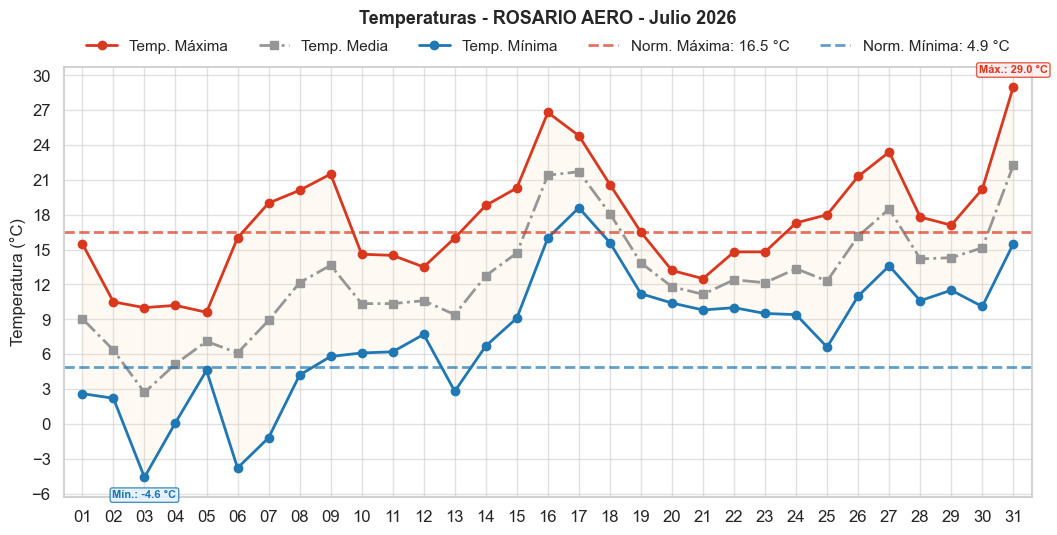

### **Resumen del mes (Julio 2026)**

1. **Valores Observados:**
   - **Temperatura Máxima Promedio:** 17.4 °C (Extremo máximo: **29.0 °C** el 31/07)
   - **Temperatura Media Promedio:** 12.5 °C
   - **Temperatura Mínima Promedio:** 7.7 °C (Extremo mínimo: **-4.6 °C** el 03/07)

2. **Valores Normales (1991-2020):**
   - **Normal Máxima:** 16.5 °C
   - **Normal Media:** 10.1 °C
   - **Normal Mínima:** 4.9 °C

3. **Anomalías Climatológicas:**
   - **Anomalía en Máximas:** +0.9 °C
   - **Anomalía en Medias:** +2.4 °C
   - **Anomalía en Mínimas:** +2.8 °C

El mes se destacó por temperaturas medias y mínimas superiores a lo normal, registrando importantes oscilaciones térmicas que incluyeron una fuerte helada al inicio del mes (-4.6 °C) y tardes muy templadas hacia el cierre del periodo.

In [62]:
consultar_agente("Mostrame un gráfico de temperaturas de Rosario durante julio de 2026")

Aquí tenés el gráfico con la evolución de las temperaturas en la estación **BARILOCHE AERO** durante **julio de 2026**, comparadas contra las líneas de normales climatológicas (1991-2020).

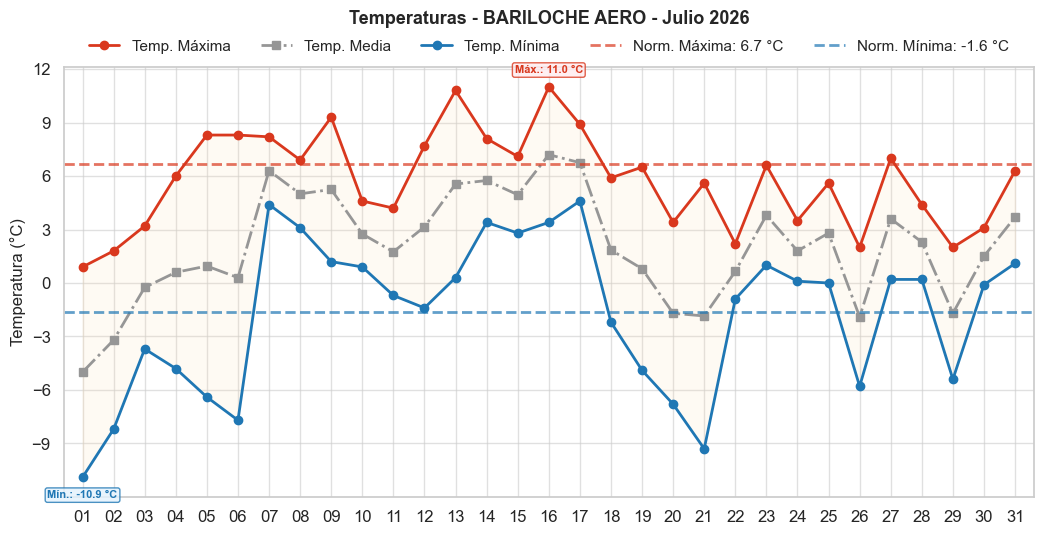

### Resumen climatológico de Julio 2026

* **Temperatura Máxima Promedio:** 5.8 °C *(Normal: 6.7 °C | Anomalía: -0.9 °C)*
* **Temperatura Media Promedio:** 2.0 °C *(Normal: 2.1 °C | Anomalía: -0.1 °C)*
* **Temperatura Mínima Promedio:** -1.7 °C *(Normal: -1.6 °C | Anomalía: -0.1 °C)*

**Extremos registrados:**
* **Temperatura máxima más alta:** 11.0 °C (registrada el 16/07)
* **Temperatura mínima más baja:** -10.9 °C (registrada el 01/07)

In [63]:
consultar_agente(
    "Graficame las temperaturas máximas de Bariloche durante julio de 2026"
)

Aquí tenés la comparación de las temperaturas máximas (y el contexto térmico general) de **Rosario Aero** para **junio y julio de 2026** frente a las normales climatológicas (1991-2020):

---

### **Junio de 2026**
* **Temperatura Máxima Promedio Observada:** **16.8 °C**
* **Normal Climatológica (Máxima):** **17.0 °C**
* **Anomalía de la Máxima:** **-0.2 °C** (ligeramente por debajo de lo normal)

**Otros datos del mes:**
* **Temperatura Media:** 11.4 °C (Normal: 11.0 °C | Anomalía: +0.4 °C)
* **Temperatura Mínima Promedio:** 6.0 °C (Normal: 6.2 °C | Anomalía: -0.2 °C)
* **Extremos:** Máxima de 23.3 °C (04/06) y mínima de -2.3 °C (24/06).

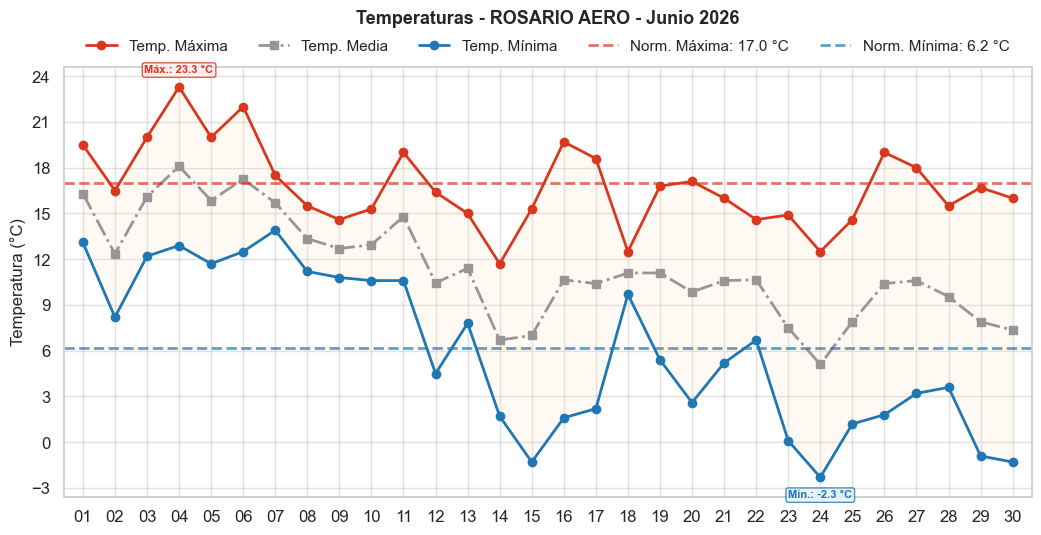

---

### **Julio de 2026**
* **Temperatura Máxima Promedio Observada:** **17.4 °C**
* **Normal Climatológica (Máxima):** **16.5 °C**
* **Anomalía de la Máxima:** **+0.9 °C** (por encima de lo normal)

**Otros datos del mes:**
* **Temperatura Media:** 12.5 °C (Normal: 10.1 °C | Anomalía: +2.4 °C)
* **Temperatura Mínima Promedio:** 7.7 °C (Normal: 4.9 °C | Anomalía: +2.8 °C)
* **Extremos:** Máxima destacada de 29.0 °C (31/07) y mínima de -4.6 °C (03/07).

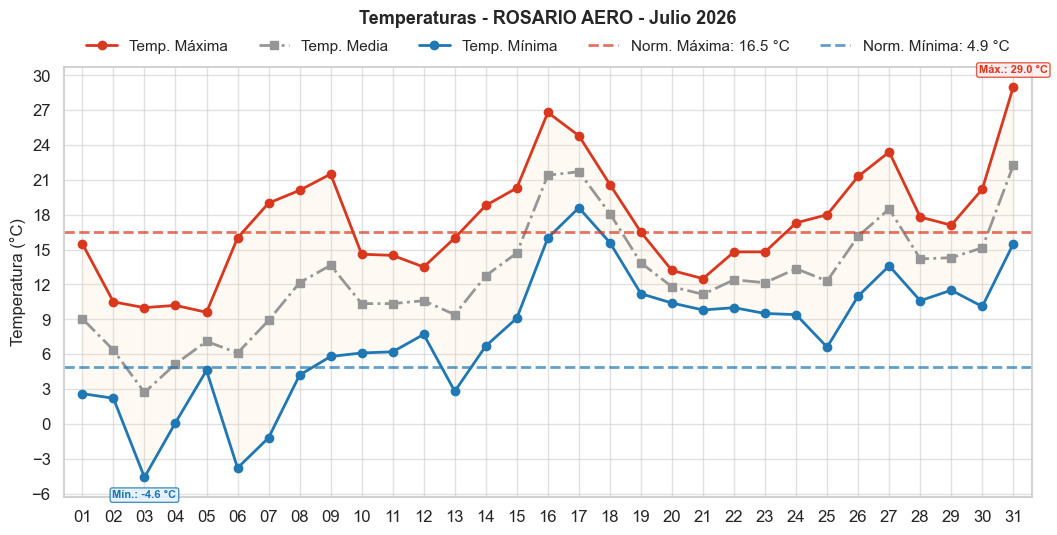

---

### **Resumen y Conclusión**
* **Junio 2026** se mantuvo muy alineado con los valores históricos, registrando temperaturas máximas prácticamente normales.
* **Julio 2026** presentó un comportamiento más cálido que el promedio histórico, especialmente en las temperaturas mínimas y medias (con anomalías cercanas a los +2.5 °C / +2.8 °C), y una máxima promedio superando la normal en casi un grado.

In [64]:
consultar_agente("Comparame la temperatura máxima de Rosario durante junio y julio de 2026 con la normal climatológica 1991-2020")

Aquí tenés el resumen comparativo de las temperaturas entre **ROSARIO AERO** y **CORDOBA AERO** durante **julio de 2026**:

### 📊 Resumen Comparativo (Julio 2026)

1. **ROSARIO AERO**
   * **Temperatura Máxima Promedio:** 17.4 °C (Extremo máximo: 29.0 °C el 31/07)
   * **Temperatura Mínima Promedio:** 7.7 °C (Extremo mínimo: -4.6 °C el 03/07)

2. **CORDOBA AERO**
   * **Temperatura Máxima Promedio:** 18.0 °C (Extremo máximo: 30.4 °C el 16/07)
   * **Temperatura Mínima Promedio:** 4.9 °C (Extremo mínimo: -3.6 °C el 06/07)

3. **Diferencias Promedio (Rosario vs. Córdoba)**
   * **Máximas:** Las temperaturas máximas promedio en Rosario fueron ligeramente inferiores (-0.7 °C) en comparación con Córdoba.
   * **Mínimas:** Las temperaturas mínimas promedio en Rosario fueron marcadamente más altas (+2.7 °C) que en Córdoba, lo que indica mañanas más templadas en Rosario o noches más frías y con mayor amplitud térmica en la ciudad mediterránea.

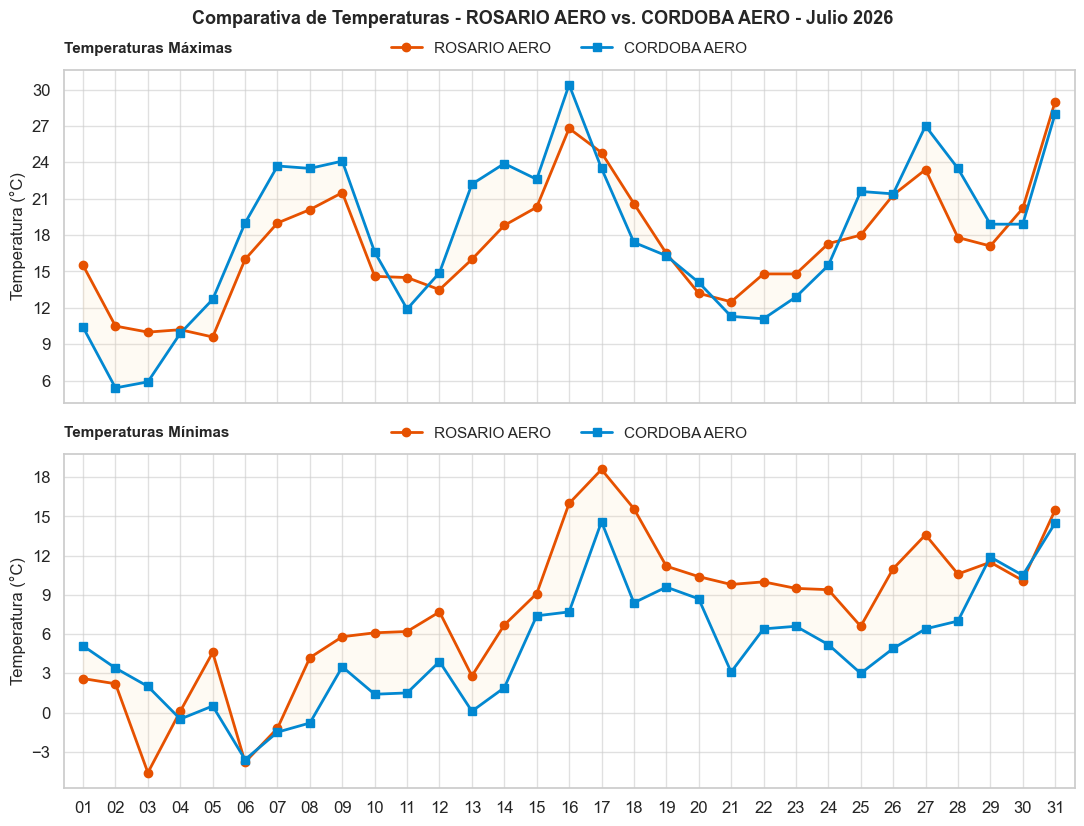

In [65]:
consultar_agente(
    "Comparame la temperatura de ROSARIO AERO y CORDOBA AERO durante julio de 2026"
)

In [ ]:
# Esta consulta es erronea, deberia responder que no hay datos
consultar_agente(
    "Graficame la temperatura de ROSARIO AERO durante enero de 1990"
)

No se encontraron registros de temperatura para la estación **ROSARIO AERO** durante el mes de enero de 1990 en la base de datos disponible. 

Si lo deseás, puedo consultar las temperaturas para otro período o de otra estación meteorológica cercana.

#### Listar estaciones

In [66]:
consultar_agente(
    "¿Qué estaciones meteorológicas hay en la provincia de Santa Fe?. ¿Y en Buenos Aires? ¿Y en CABA?"
)

A continuación se detallan las estaciones meteorológicas del Servicio Meteorológico Nacional (SMN) para cada una de las regiones solicitadas:

### 📍 Provincia de Santa Fe (7 estaciones)
*   **CERES AERO** (OACI: SANW)
*   **RAFAELA AERO** (OACI: SAFR)
*   **RECONQUISTA AERO** (OACI: SATR)
*   **ROSARIO AERO** (OACI: SAAR)
*   **SAUCE VIEJO AERO** (OACI: SAAV)
*   **SUNCHALES AERO** (OACI: SAFS)
*   **VENADO TUERTO AERO** (OACI: SAFV)

---

### 📍 Provincia de Buenos Aires (26 estaciones)
*   **AZUL AERO** (OACI: SAZA)
*   **BAHIA BLANCA AERO** (OACI: SAZB)
*   **BENITO JUAREZ AERO** (OACI: SAZJ)
*   **BOLIVAR AERO** (OACI: SAZI)
*   **CAMPO DE MAYO AERO** (OACI: SADO)
*   **CORONEL SUAREZ AERO** (OACI: SAZC)
*   **DOLORES AERO** (OACI: SAZD)
*   **EL PALOMAR AERO** (OACI: SADP)
*   **EZEIZA AERO** (OACI: SAEZ)
*   **JUNIN AERO** (OACI: SAAJ)
*   **LA PLATA AERO** (OACI: SADL)
*   **LAS FLORES** (OACI: SAEL)
*   **MAR DEL PLATA AERO** (OACI: SAZM)
*   **MARIANO MORENO AERO** (OACI: SADJ)
*   **MERLO AERO** (OACI: SADR)
*   **MORON AERO** (OACI: SADM)
*   **NUEVE DE JULIO** (OACI: SAZX)
*   **OLAVARRIA AERO** (OACI: SAZF)
*   **PEHUAJO AERO** (OACI: SAZP)
*   **PIGUE AERO** (OACI: SAZE)
*   **PUNTA INDIO B.A.** (OACI: SAAI)
*   **SAN FERNANDO AERO** (OACI: SADF)
*   **TANDIL AERO** (OACI: SAZT)
*   **TRENQUE LAUQUEN** (OACI: SAET)
*   **TRES ARROYOS** (OACI: SAZH)
*   **VILLA GESELL AERO** (OACI: SAZV)

---

### 📍 Ciudad Autónoma de Buenos Aires - CABA (2 estaciones)
*   **AEROPARQUE AERO** (OACI: SABE)
*   **BUENOS AIRES OBSERVATORIO** (OACI: SABA)

In [22]:
consultar_agente(
    "Dame la ubicación, altura y códigos de la estación Rosario, y las de Jujuy (provincia)"
)

Aquí tenés la información detallada de ubicación, altura y códigos de las estaciones solicitadas:

### 📍 Estación Rosario (Provincia de Santa Fe)
* **Estación:** ROSARIO AERO
* **Provincia:** Santa Fe
* **Ubicación:** Latitud -32.9°, Longitud -60.77°
* **Altura:** 25 metros
* **Códigos:** 
  * N° SMN: 87480
  * OACI: SAAR

---

### 📍 Estaciones de la Provincia de Jujuy

1. **JUJUY AERO**
   * **Ubicación:** Latitud -24.38°, Longitud -65.08°
   * **Altura:** 909 metros
   * **Códigos:** 
     * N° SMN: 87046
     * OACI: SASJ

2. **JUJUY U N**
   * **Ubicación:** Latitud -24.17°, Longitud -65.32°
   * **Altura:** 1302 metros
   * **Códigos:** 
     * N° SMN: 87043
     * OACI: *No disponible (nan)*

3. **LA QUIACA OBSERVATORIO**
   * **Ubicación:** Latitud -22.10°, Longitud -65.60°
   * **Altura:** 3459 metros
   * **Códigos:** 
     * N° SMN: 87007
     * OACI: SASQ

#### Consultas a la base vectorial

In [67]:
consultar_agente("Qué documentos tenés disponibles para consultar?")

Tengo disponibles los siguientes informes climáticos oficiales del Servicio Meteorológico Nacional correspondientes al año 2026:

* **Informes Mensuales:**
  * Enero 2026 (`Clim-Enero 2026.pdf`)
  * Febrero 2026 (`Clim-Febrero 2026.pdf`)
  * Marzo 2026 (`Clim-Marzo 2026.pdf`)
  * Abril 2026 (`Clim-Abril 2026.pdf`)
  * Mayo 2026 (`Clim-Mayo 2026.pdf`)
  * Junio 2026 (`Clim-Junio 2026.pdf`)
  * Julio 2026 (`Clim-Julio 2026.pdf`)

* **Informes Estacionales:**
  * Verano 2025-2026 (`Clim-Verano 2025-26.pdf`)
  * Otoño 2026 (`Clim-Otoño 2026.pdf`)

Podés consultarme sobre el contenido de estos documentos para analizar eventos climáticos, resúmenes de temperatura, precipitaciones y anomalías registradas en dichos períodos.

In [49]:
consultar_agente("Según los informes del SMN, ¿cómo fueron las precipitaciones durante mayo de 2026?. Además, cómo se compararon con otoño 2026?")

Según los informes del Servicio Meteorológico Nacional (SMN) para el año 2026, las características de las precipitaciones en **mayo de 2026** y su relación con el contexto general del **otoño de 2026** se detallan a continuación:

### **Precipitaciones en Mayo de 2026**
* **Escasez generalizada:** Gran parte del país (incluyendo el Noroeste Argentino - NOA, Cuyo y el centro/zona central de la Patagonia) registró acumulados inferiores a los 20 mm. En varias localidades, como La Quiaca o Ceres, **no se registraron precipitaciones** durante todo el mes.
* **Frecuencia de días con lluvia:** Predominaron las anomalías negativas en la cantidad de días con precipitaciones en gran parte del territorio nacional (con menores registros en zonas como Dolores, Concordia y Ezeiza).
* **Eventos extremos puntuales:** A pesar de la sequía predominante, se destacaron algunos eventos aislados de lluvias y tormentas fuertes en Chaco, el este de Buenos Aires y el norte de Entre Ríos. 
* **Excepciones húmedas:** Los mayores acumulados diarios y desvíos positivos se registraron de manera muy localizada, destacándose la zona cordillerana de Neuquén (con registros superiores a los 300-500 mm en puntos específicos como Cerro Mirador) y algunos sectores de la provincia de Buenos Aires (como Tres Arroyos y Mar del Plata).

---

### **Comparación con el Otoño de 2026 (Marzo, Abril y Mayo)**
* **Comportamiento estacional vs. mensual:** Mientras que mayo se caracterizó por una marcada escasez de lluvias y anomalías negativas generalizadas, el **otoño de 2026 en su conjunto** presentó acumulados muy significativos.
* **Volúmenes acumulados estacionales:** Durante toda la estación otoñal, las precipitaciones superaron los **400 mm** en amplias regiones del norte y centro del país (como gran parte de Formosa y Chaco, norte de Corrientes y Santa Fe, sudeste de Santiago del Estero y el centro de Buenos Aires), evidenciando que los meses previos (marzo y/o abril) compensaron con creces la sequía experimentada en el tramo final del otoño (mayo).

#### Mapas de provincias / país

Aquí tenés los mapas con la distribución de las estaciones meteorológicas del SMN para las regiones solicitadas y a nivel nacional:

### Provincia de Buenos Aires

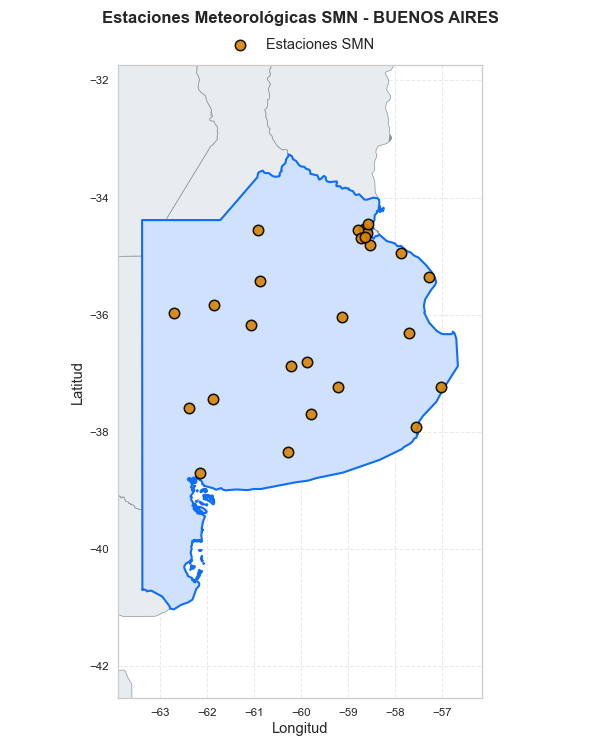

### Provincia de Tierra del Fuego

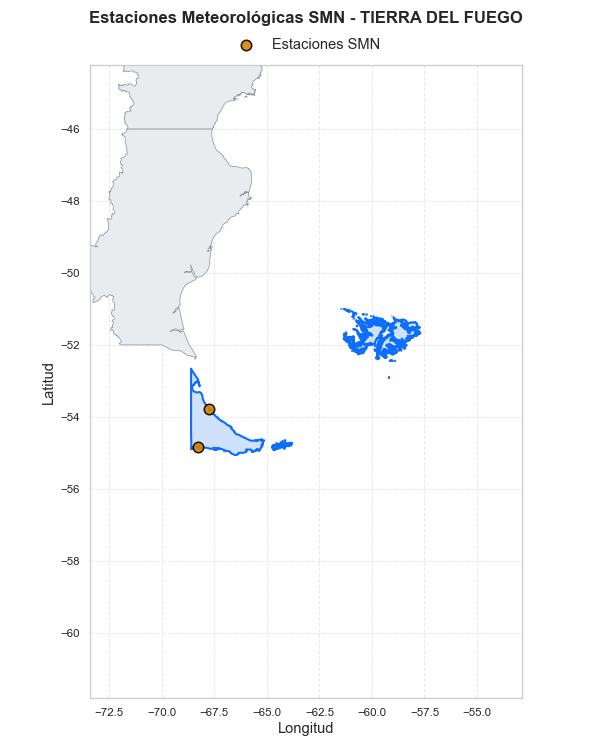

### Antártida

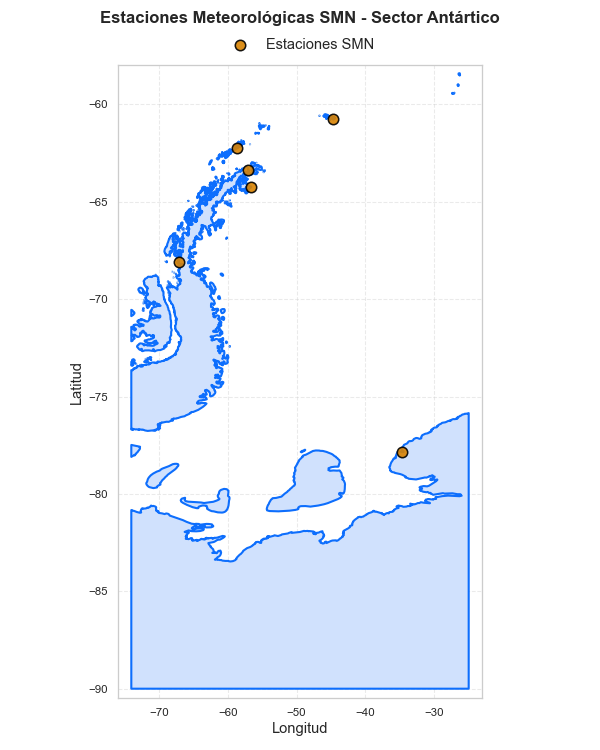

### Todo el País

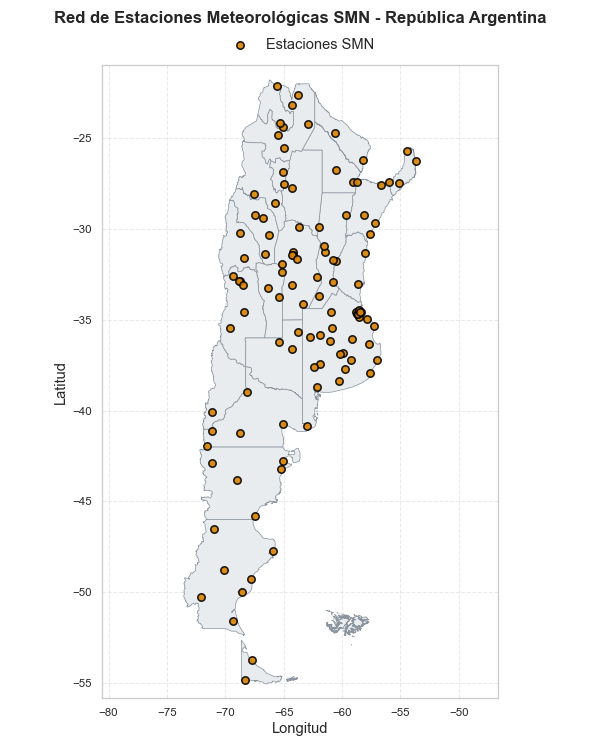

In [140]:
consultar_agente(
  "Quisiera ver un mapa de las estaciones meteorologicas en buenos aires, antartida, tierra del fuego, y todo el pais"
)

#### Climogramas

Aquí tenés los climogramas correspondientes a las estaciones meteorológicas solicitadas, que muestran la marcha anual de las temperaturas medias y las precipitaciones mensuales:

### Rosario

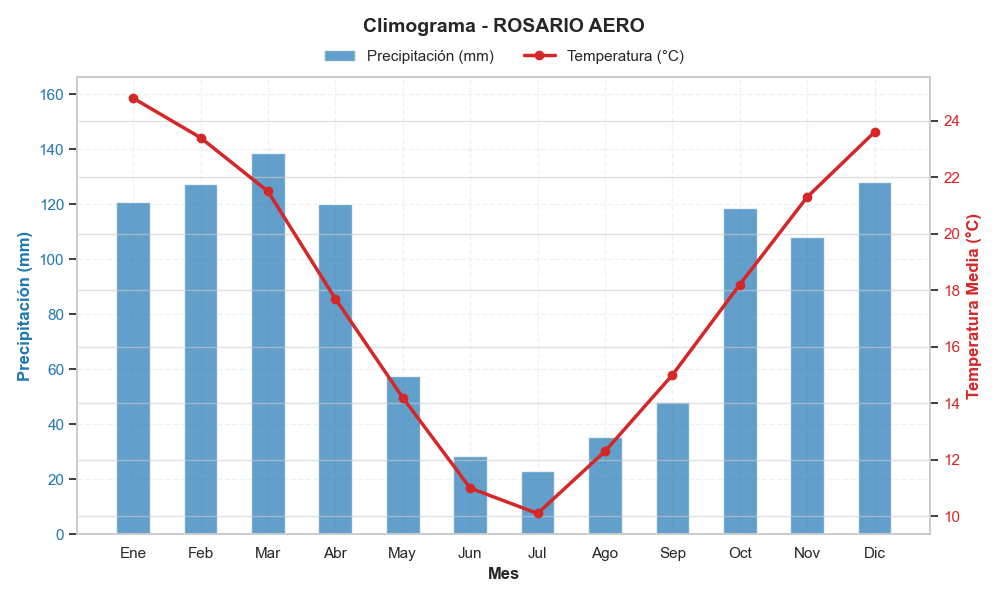

---

### La Quiaca

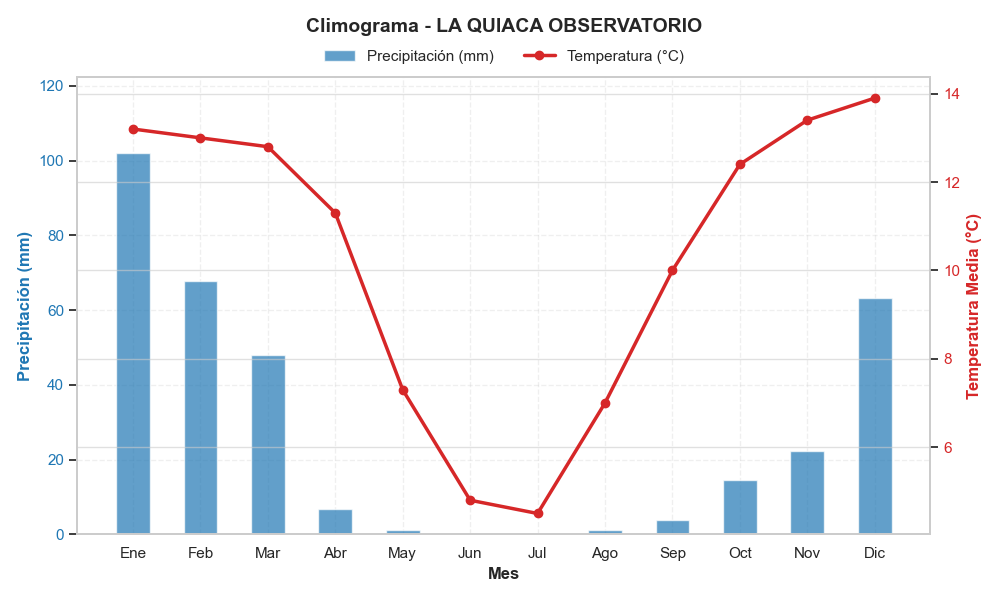

---

### Ushuaia

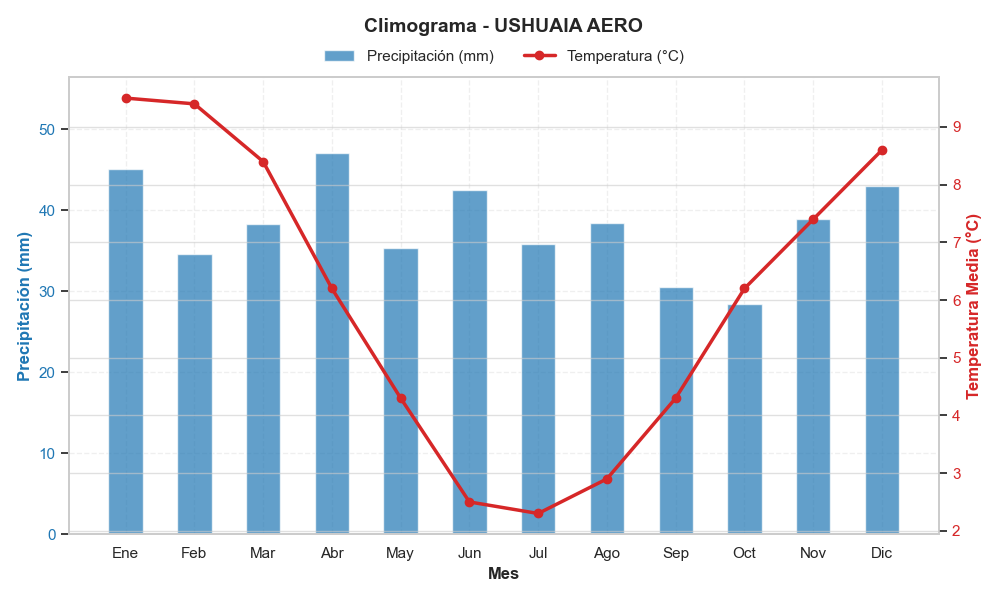

In [141]:
consultar_agente("Quisiera ver los climogramas de Rosario, La Quiaca y Ushuaia")

#### Pronosticos

A continuación, te presento el pronóstico a 5 días para **Rosario Aero** y su comparación con **Sauce Viejo Aero** (provincia de Santa Fe):

### 1. Pronóstico para Rosario Aero (04/10/2026 al 08/10/2026)

* **Condiciones recientes (03/10):** Máxima de **21.0 °C**, mínima de **12.7 °C**.
* **Temperaturas pronosticadas:**
  * **Mínima absoluta esperada:** **9.9 °C** (el 04/10).
  * **Máxima absoluta esperada:** **24.7 °C** (el 06/10).
  * **Temperatura promedio:** **16.1 °C** (tendencia estable).
* **Precipitaciones:**
  * **Acumulado total esperado:** **49.2 mm** concentrados en precipitaciones durante el período.

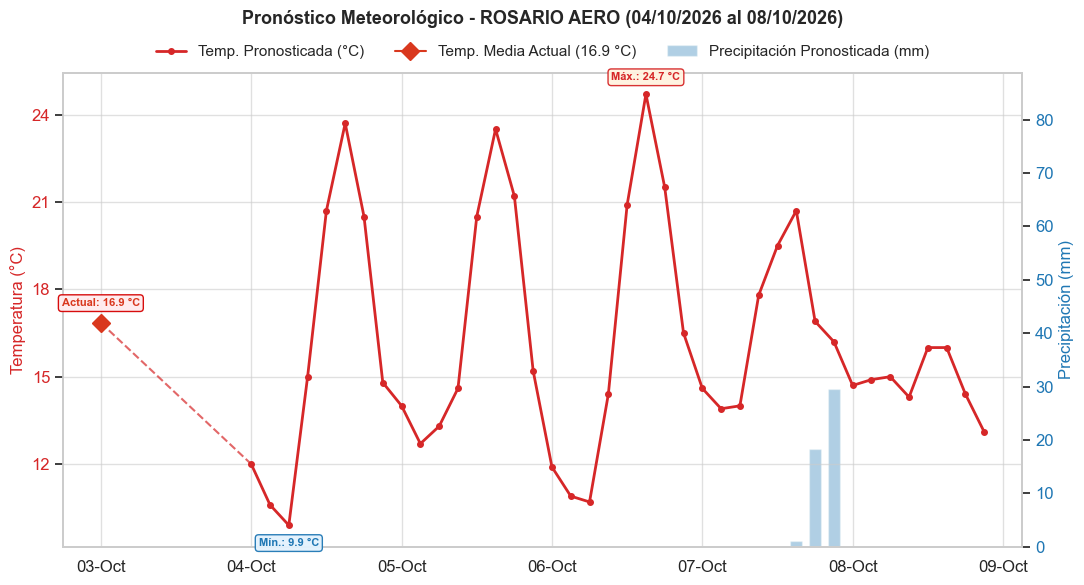

---

### 2. Pronóstico para Sauce Viejo Aero (04/10/2026 al 08/10/2026)

* **Condiciones recientes (03/10):** Máxima de **21.6 °C**, mínima de **14.0 °C**.
* **Temperaturas pronosticadas:**
  * **Mínima absoluta esperada:** **9.7 °C** (el 04/10).
  * **Máxima absoluta esperada:** **24.2 °C** (el 06/10).
  * **Temperatura promedio:** **17.3 °C** (tendencia estable).
* **Precipitaciones:**
  * **Acumulado total esperado:** **3.8 mm** acumulados en el período.

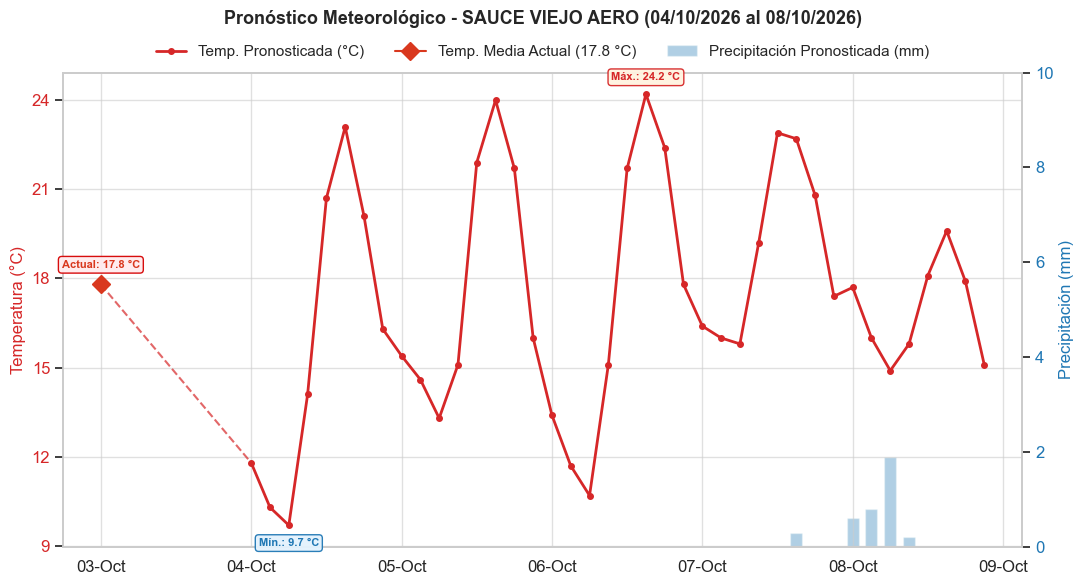

---

### Conclusión comparativa
Ambas estaciones muestran un comportamiento térmico muy similar durante los próximos días, con marcas mínimas cercanas a los **9.7 °C - 9.9 °C** y picos máximos que rondarán los **24 °C - 24.7 °C** hacia el 6 de octubre, manteniendo una tendencia general estable. Sin embargo, en cuanto a las precipitaciones, **Rosario Aero** presenta un pronóstico significativamente más húmedo con **49.2 mm** previstos, frente a los escasos **3.8 mm** esperados en **Sauce Viejo Aero**.

In [69]:
consultar_agente("Quiero ver el pronostico para Rosario, y comparalo con el de otra estacion en santa fe, a tu eleccion")

#### Consultas complejas con múltiples herramientas 

A continuación, te presento el detalle solicitado sobre las temperaturas en Rosario, las estaciones meteorológicas de Santa Fe y la ola de frío registrada en 2026:

### 1. Evolución de las temperaturas en Rosario durante Julio de 2026

Durante el mes de julio de 2026, la estación **Rosario Aero** registró los siguientes valores promedio y extremos:
* **Temperatura Máxima Promedio:** 17.4 °C (con un extremo máximo de **29.0 °C** registrado el 31/07).
* **Temperatura Media Promedio:** 12.5 °C.
* **Temperatura Mínima Promedio:** 7.7 °C (con un extremo mínimo de **-4.6 °C** alcanzado el 03/07).

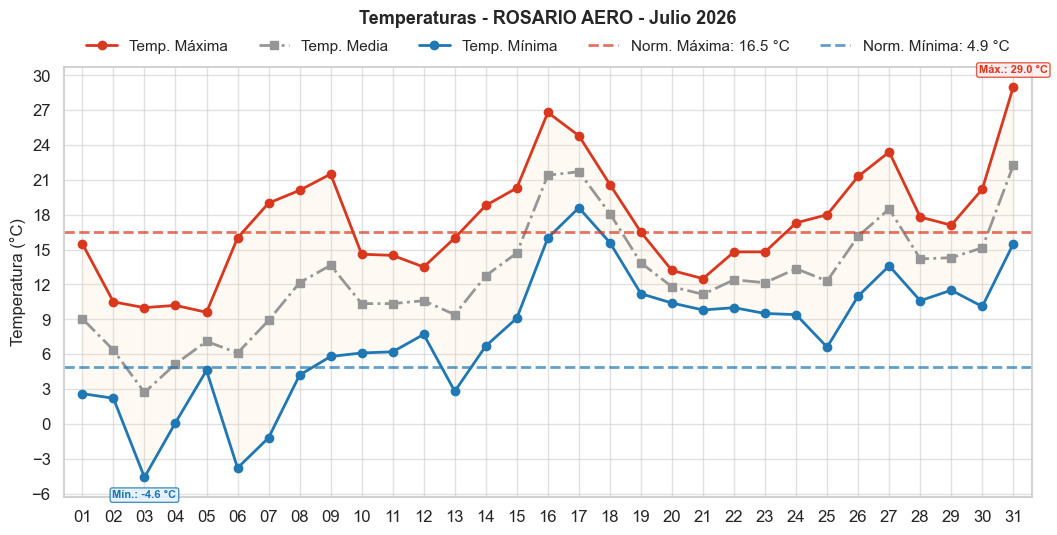

---

### 2. Comparación con las temperaturas normales (1991-2020)

Al comparar los valores observados con el período de referencia climatológico normal para el mes de julio, se observa un comportamiento **más cálido que el promedio** en términos generales:
* **Máximas:** La normal es de 16.5 °C, por lo que hubo una anomalía leve de **+0.9 °C**.
* **Medias:** La normal es de 10.1 °C, registrando una anomalía de **+2.4 °C**.
* **Mínimas:** La normal es de 4.9 °C, lo que representa una anomalía significativa de **+2.8 °C**.

---

### 3. Estaciones meteorológicas en Santa Fe y mapa de ubicación

En la provincia de Santa Fe se encuentran operativas **7 estaciones meteorológicas** oficiales del Servicio Meteorológico Nacional (SMN):
1. **Ceres Aero**
2. **Rafaela Aero**
3. **Reconquista Aero**
4. **Rosario Aero**
5. **Sauce Viejo Aero**
6. **Sunchales Aero**
7. **Venado Tuerto Aero**

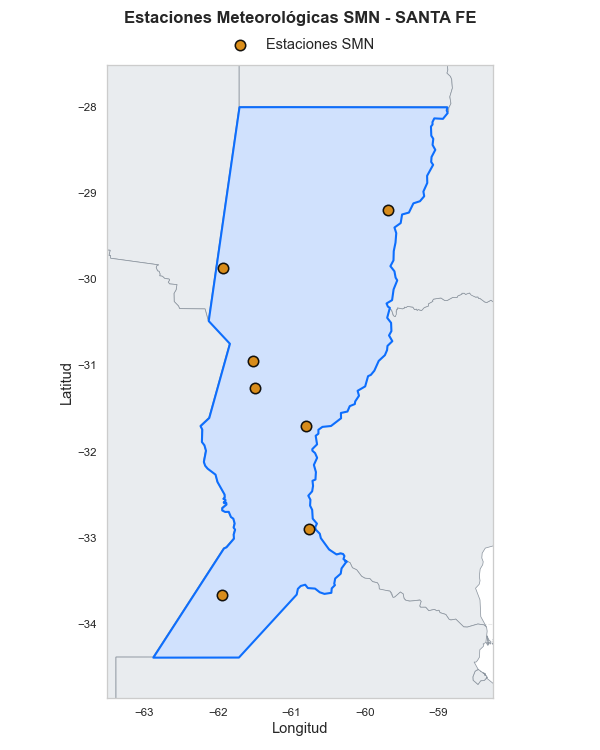

---

### 4. Descripción de la ola de frío de 2026

Según los informes climatológicos de julio de 2026, se registraron **dos eventos principales de olas de frío** a nivel nacional:

* **Primer evento (1 al 5 de julio):** 
  * Se caracterizó por temperaturas máximas y mínimas que igualaron o cayeron por debajo de los umbrales locales (percentil 10) durante al menos 3 días consecutivos y de forma simultánea.
  * El día **3 de julio** se alcanzó el pico de afectación con cerca de **50 localidades** bajo condiciones de ola de frío en el país (coincidiendo con la mínima extrema de -4.6 °C registrada en Rosario).
  * Varias localidades de la provincia de Buenos Aires y la región central registraron duraciones de entre 4 y 5 días con mínimas muy bajas (por ejemplo, Las Flores con -4.9 °C).

* **Segundo evento (18 al 31 de julio):** 
  * Fue un período prolongado e intenso de bajas temperaturas, especialmente notable en la región patagónica y el sur del país.
  * Localidades como **El Calafate** sufrieron 14 días consecutivos de ola de frío (del 18 al 31) con marcas mínimas extremas de hasta **-17.6 °C**, mientras que Perito Moreno registró temperaturas mínimas de **-19.5 °C**.
  * En diversos sectores, las temperaturas máximas no superaron los 0 °C, provocando el congelamiento de suelos y superficies de agua, así como la caída de nieve en la región.

In [68]:
consultar_agente(
  """Hola, necesito que respondas a lo siguiente:
  - Como evolucionaron las temperaturas en Rosario durante Julio de 2026?
  - Y como se compara con las temperaturas normales?
  - Cuantas estaciones meteorologicas hay en Santa Fe? Tambien quisiera ver un mapa para saber en donde se encuentran.
  - Por ultimo, quisiera que describas la ola de frio que ocurrio en 2026.
  """
)

#### Consultas interactivas

🤖 Asistente Meteorológico SMN - Sesión Interactiva Iniciada
Escribí 'salir', 'exit' o 'chau' para terminar la conversación.



**👤 Usuario:** De que estaba hablando?


🤖 Agente:


Parece que esta es nuestra primera interacción o que la conversación anterior se ha reiniciado, ya que no tengo registro de lo que estabas comentando previamente. 

¿De qué te gustaría que hablemos o en qué te puedo ayudar? 

Para que sepas de qué disponemos, puedo ayudarte con:
* **Consultas de estaciones meteorológicas** (buscar estaciones por provincia o nombre, u obtener su ubicación y altura).
* **Análisis y gráficos de temperatura** (generar gráficos de temperaturas máximas y mínimas para un rango de fechas).
* **Comparaciones térmicas** (comparar temperaturas entre dos estaciones o contra las normales climatológicas 1991-2020).
* **Mapas** (generar mapas con la ubicación de las estaciones a nivel nacional o filtradas por provincia).
* **Informes climáticos** (buscar explicaciones conceptuales y detalles de informes meteorológicos almacenados).

¡Contame qué tema tenías en mente y lo retomamos!

------------------------------------------------------------


**👤 Usuario:** Mostrame un mapa de las estaciones de buenos aires, tambien una lista


🤖 Agente:


Aquí tenés el mapa con la ubicación de las estaciones meteorológicas en la provincia de Buenos Aires:

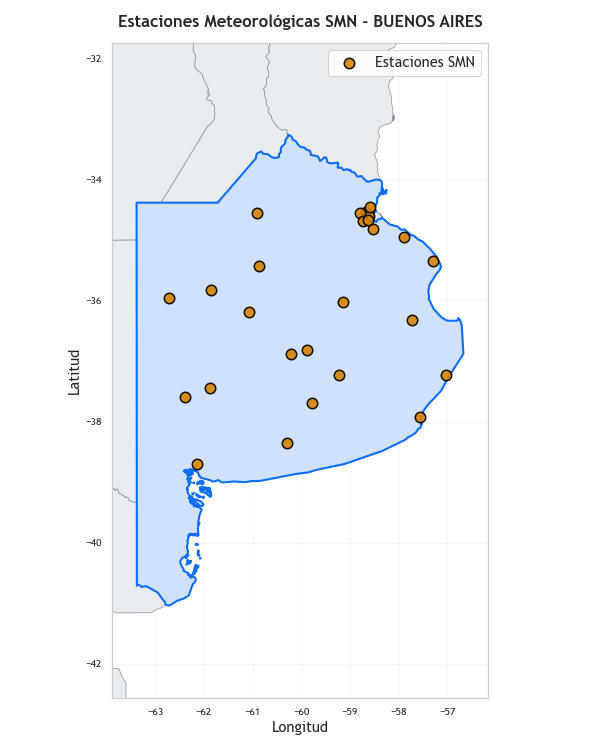

Y a continuación, el listado de las estaciones disponibles en la provincia (mostrando las primeras 20):

* **AZUL AERO** — Lat: -36.82° | Lon: -59.88° | Altura: 147 m | OACI: SAZA
* **BAHIA BLANCA AERO** — Lat: -38.70° | Lon: -62.15° | Altura: 83 m | OACI: SAZB
* **BENITO JUAREZ AERO** — Lat: -37.70° | Lon: -59.78° | Altura: 207 m | OACI: SAZJ
* **BOLIVAR AERO** — Lat: -36.18° | Lon: -61.07° | Altura: 94 m | OACI: SAZI
* **CAMPO DE MAYO AERO** — Lat: -34.53° | Lon: -58.67° | Altura: 26 m | OACI: SADO
* **CORONEL SUAREZ AERO** — Lat: -37.45° | Lon: -61.88° | Altura: 233 m | OACI: SAZC
* **DOLORES AERO** — Lat: -36.32° | Lon: -57.72° | Altura: 9 m | OACI: SAZD
* **EL PALOMAR AERO** — Lat: -34.60° | Lon: -58.60° | Altura: 12 m | OACI: SADP
* **EZEIZA AERO** — Lat: -34.82° | Lon: -58.53° | Altura: 20 m | OACI: SAEZ
* **JUNIN AERO** — Lat: -34.55° | Lon: -60.92° | Altura: 81 m | OACI: SAAJ
* **LA PLATA AERO** — Lat: -34.95° | Lon: -57.88° | Altura: 23 m | OACI: SADL
* **LAS FLORES** — Lat: -36.03° | Lon: -59.13° | Altura: 36 m | OACI: SAEL
* **MAR DEL PLATA AERO** — Lat: -37.92° | Lon: -57.57° | Altura: 21 m | OACI: SAZM
* **MARIANO MORENO AERO** — Lat: -34.55° | Lon: -58.78° | Altura: 32 m | OACI: SADJ
* **MERLO AERO** — Lat: -34.68° | Lon: -58.73° | Altura: 24 m | OACI: SADR
* **MORON AERO** — Lat: -34.67° | Lon: -58.63° | Altura: 24 m | OACI: SADM
* **NUEVE DE JULIO** — Lat: -35.43° | Lon: -60.87° | Altura: 76 m | OACI: SAZX
* **OLAVARRIA AERO** — Lat: -36.88° | Lon: -60.22° | Altura: 166 m | OACI: SAZF
* **PEHUAJO AERO** — Lat: -35.83° | Lon: -61.85° | Altura: 87 m | OACI: SAZP
* **PIGUE AERO** — Lat: -37.60° | Lon: -62.38° | Altura: 304 m | OACI: SAZE

------------------------------------------------------------


**👤 Usuario:** Podes hacer lo mismo para la antartida?


🤖 Agente:


Aquí tenés el mapa con la ubicación de las estaciones meteorológicas en el sector antártico:

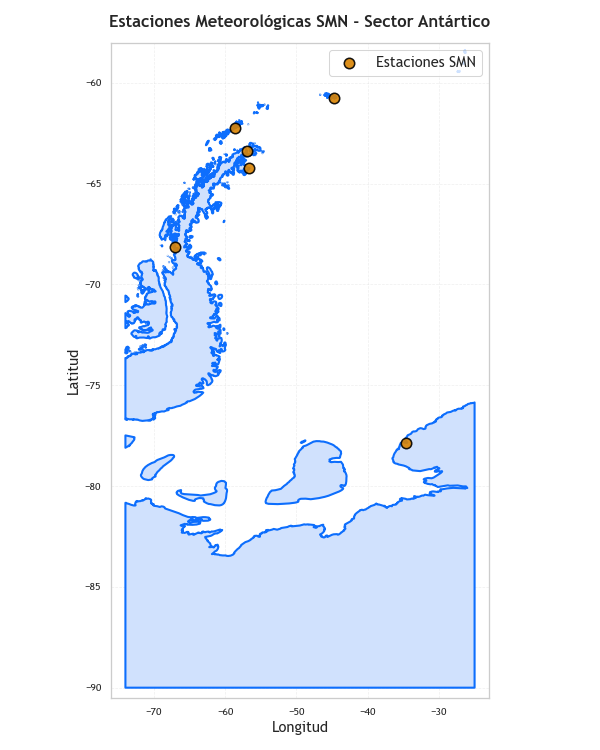

Y a continuación, el listado completo de las estaciones disponibles en la Antártida:

* **BASE BELGRANO II** — Lat: -77.87° | Lon: -34.62° | Altura: 256 m | OACI: SAYB
* **BASE CARLINI (EX JUBANY)** — Lat: -62.23° | Lon: -58.65° | Altura: 11 m | OACI: SAYJ
* **BASE ESPERANZA** — Lat: -63.38° | Lon: -56.98° | Altura: 24 m | OACI: SAYE
* **BASE MARAMBIO** — Lat: -64.23° | Lon: -56.62° | Altura: 198 m | OACI: SAWB
* **BASE ORCADAS** — Lat: -60.73° | Lon: -44.73° | Altura: 12 m | OACI: SAYO
* **BASE SAN MARTIN** — Lat: -68.12° | Lon: -67.10° | Altura: 7 m | OACI: SAYS

------------------------------------------------------------

👋 Sesión finalizada. ¡Hasta luego!



In [71]:
iniciar_chat_interactivo()

In [25]:
iniciar_chat_interactivo()

🤖 Asistente Meteorológico SMN - Sesión Interactiva Iniciada
Escribí 'salir', 'exit' o 'chau' para terminar la conversación.



**👤 Usuario:** Dame una receta de panqueques, aparte de eso quiero una lista de estaciones en CABA


🤖 Agente:


### Receta clásica de panqueques (para dulce o salado)

**Ingredientes:**
* 1 taza de harina leudante (o harina común con 1 cucharadita de polvo para hornear)
* 1 taza de leche
* 1 huevo
* 1 pizca de sal (o 1 cucharadita de azúcar si los preferís dulces)
* Manteca o aceite para lubricar la sartén

**Preparación:**
1. En un bol, colocá el huevo y batilo ligeramente.
2. Agregá la mitad de la leche y la harina tamizada de a poco, batiendo constantemente para evitar que se formen grumos.
3. Incorporá el resto de la leche y la pizca de sal (o azúcar). Mezclá bien hasta obtener una preparación líquida y homogénea.
4. Calentá una sartén (idealmente antiadherente) a fuego medio y pasale un poquito de manteca o aceite.
5. Verté un cucharón chico de mezcla en el centro de la sartén y movela rápidamente para cubrir toda la base de forma pareja.
6. Cociná durante 1 o 2 minutos hasta que los bordes se doren y se desprendan solos. Dalo vuelta y cociná unos segundos más del otro lado.
7. Repetite el proceso hasta terminar la mezcla. ¡Listo para rellenar con dulce de leche, jamón y queso, o lo que prefieras!

---

### Estaciones meteorológicas en CABA (Ciudad Autónoma de Buenos Aires)

Según los registros del Servicio Meteorológico Nacional (SMN), en la Ciudad Autónoma de Buenos Aires se encuentran las siguientes estaciones:

1. **AEROPARQUE AERO**
   * **Provincia:** Capital Federal
   * **Latitud:** -34.55 | **Longitud:** -58.42
   * **Altura:** 6 m
   * **Código SMN:** 87582.0 | **OACI:** SABE

2. **BUENOS AIRES OBSERVATORIO**
   * **Provincia:** Capital Federal
   * **Latitud:** -34.58 | **Longitud:** -58.48
   * **Altura:** 25 m
   * **Código SMN:** 87585.0 | **OACI:** SABA

------------------------------------------------------------


...

------------------------------------------------------------


**👤 Usuario:** Entonces los panqueques los puedo rellenar con dulce de leche?


🤖 Agente:


¡Jaja! En el terreno culinario gastronómico seguro que sí, ¡con dulce de leche quedan riquísimos! Pero por el lado de la atmósfera y la meteorología, te cuento que por acá no tenemos ninguna "masa de aire caliente" ni "frente frío" que se le parezca a un panqueque, ¡aunque a veces las nubes altas y delgadas (como los cirros) parezcan sábanas finitas!

Si volvemos a la atmósfera real, ¿te gustaría que analicemos alguna estación meteorológica, comparemos temperaturas o veamos algún informe del clima? ¡Para eso sí que estoy listo!

------------------------------------------------------------

👋 Sesión finalizada. ¡Hasta luego!

